# CA-PC-DRFM v4 — Rigorous Full Experiment on UCI Online Retail I

Notebook nghiên cứu cho đề tài **Phân tích và dự báo hành vi khách hàng sử dụng mô hình Dynamic RFM**.

Phiên bản v4 tập trung vào: (1) benchmark được tách đúng quy tắc nhãn công bố và đánh giá survival có censoring; (2) bổ sung Cox Proportional Hazards làm baseline survival; (3) giữ đúng các quan sát trùng dòng ở benchmark chính và chạy audit độ nhạy dedup; (4) báo cáo threshold đã chọn trên Validation, F1 oracle chỉ để tham khảo, Lift@Top-10%, customer-cluster bootstrap và kiểm định rõ ràng.

**Không có cam kết trước rằng CA-PC-DRFM sẽ vượt mọi nghiên cứu.** Kết luận chỉ dựa trên kết quả chạy thật; không dùng Test để chọn mô hình hoặc threshold.

## 0. Chuẩn bị môi trường và cài đặt thư viện


In [96]:
# Bootstrap nguồn dự án v4 — source mới luôn được đồng bộ, tránh import src cũ.
from pathlib import Path
import base64
import io
import os
import sys
import zipfile
import shutil
import tempfile
import importlib
import inspect

_EMBEDDED_SOURCE_ZIP = base64.b64decode("""
...
""")

# Colab: luôn dùng /content/ca_pc_drfm; local: nếu đang ở project folder thì không tạo project lồng nhau.
_RUNTIME_ROOT = Path("/content") if Path("/content").exists() else Path.cwd().resolve()
if _RUNTIME_ROOT.name == "ca_pc_drfm":
    _RUNTIME_ROOT = _RUNTIME_ROOT.parent
PROJECT_DIR = _RUNTIME_ROOT / "ca_pc_drfm"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

with tempfile.TemporaryDirectory(prefix="ca_pc_drfm_source_v4_") as _tmp_dir:
    _tmp_root = Path(_tmp_dir)
    with zipfile.ZipFile(io.BytesIO(_EMBEDDED_SOURCE_ZIP), "r") as _archive:
        for _member in _archive.infolist():
            _member_path = Path(_member.filename)
            if _member_path.is_absolute() or ".." in _member_path.parts:
                raise RuntimeError(f"Đường dẫn không an toàn trong source bundle: {_member.filename}")
        _archive.extractall(_tmp_root)
    _fresh_project = _tmp_root / "ca_pc_drfm"
    if not (_fresh_project / "src" / "config.py").is_file():
        raise FileNotFoundError("Source bundle nhúng không có ca_pc_drfm/src/config.py")
    _target_src = PROJECT_DIR / "src"
    if _target_src.exists():
        shutil.rmtree(_target_src)
    shutil.copytree(_fresh_project / "src", _target_src)
    _target_tests = PROJECT_DIR / "tests"
    if _target_tests.exists():
        shutil.rmtree(_target_tests)
    shutil.copytree(_fresh_project / "tests", _target_tests)
    for _name in ("requirements.txt", "README.md", ".gitignore"):
        _src_file = _fresh_project / _name
        if _src_file.is_file():
            shutil.copy2(_src_file, PROJECT_DIR / _name)

for _module_name in list(sys.modules):
    if _module_name == "src" or _module_name.startswith("src."):
        del sys.modules[_module_name]
sys.path = [p for p in sys.path if not p or Path(p).resolve() != PROJECT_DIR]
sys.path.insert(0, str(PROJECT_DIR))
importlib.invalidate_caches()
os.chdir(PROJECT_DIR)

from src.config import Config
_config_parameters = inspect.signature(Config).parameters
_required = {"train_end_date", "validation_end_date", "snapshot_frequency_days", "horizon_days", "deduplicate_exact_lines"}
_missing = sorted(_required - set(_config_parameters))
if _missing:
    raise TypeError("Config v4 vẫn thiếu tham số: " + ", ".join(_missing))
print("Project directory:", PROJECT_DIR)
print("Source version: CA-PC-DRFM v4")
print("Config source:", inspect.getfile(Config))
print("Source code + tests đã đồng bộ; data/ và results/ được giữ nguyên.")

Project directory: /content/ca_pc_drfm
Source version: CA-PC-DRFM v4
Config source: /content/ca_pc_drfm/src/config.py
Source code + tests đã đồng bộ; data/ và results/ được giữ nguyên.


In [97]:
%pip install -q -r requirements.txt
%pip install -q pytest
print("Dependencies installed for full CA-PC-DRFM v4 experiment.")

Dependencies installed for full CA-PC-DRFM v4 experiment.


## 1. Import và cấu hình thực nghiệm

In [98]:
import json
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay,
    average_precision_score, roc_auc_score, brier_score_loss,
)

from src.config import Config
from src.data import download_online_retail, load_raw_data, preprocess_transactions, save_processed_data
from src.features import build_all_invoice_states, get_model_features
from src.survival import (
    chronological_snapshot_split,
    attach_time_to_event,
    build_person_period,
    make_horizon_label,
    make_paper_protocol_labels,
)
from src.models import make_binary_models, make_hazard_model, HAS_LIGHTGBM
from src.cox import CoxPHRiskModel, select_cox_features
from src.evaluation import (
    binary_metrics,
    choose_threshold,
    customer_bootstrap_delta_ap_multi,
    customer_cluster_bootstrap_metrics_multi,
    customer_balanced_binary_metrics,
    harrell_c_index_at_horizon,
    kaplan_meier_purchase_probability,
    paired_seed_tests,
    predict_hazard_risk,
    top_fraction_metrics,
)

if not HAS_LIGHTGBM:
    raise ImportError(
        "Không import được LightGBM. Hãy chạy lại cell cài đặt requirements.txt. "
        "Notebook không thay LightGBM bằng estimator khác để tránh gắn nhãn mô hình sai."
    )

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")

# FULL EXPERIMENT — không có nhánh Quick Run.
SEEDS = [42, 43, 44, 45, 46]
N_ESTIMATORS = 300
BOOTSTRAP_REPEATS = 1000

DATA_PATH = None  # None: tự tải Online Retail I từ UCI; hoặc Path('/content/Online Retail.xlsx').
RESULTS_DIR = PROJECT_DIR / "results"
DATA_DIR = PROJECT_DIR / "data" / "raw"

cfg = Config(
    project_dir=PROJECT_DIR,
    data_dir=DATA_DIR,
    results_dir=RESULTS_DIR,
    dataset_path=DATA_PATH,
    snapshot_frequency_days=7,
    minimum_history_days=60,
    train_end_date="2011-09-01",
    validation_end_date="2011-10-16",
    horizon_days=90,
    classification_horizon_days=30,
    cycle_shrinkage_strength=2.0,
    deduplicate_exact_lines=False,  # primary benchmark preserves exact rows; dedup is audited separately
    seeds=SEEDS,
    n_estimators=N_ESTIMATORS,
    bootstrap_repeats=BOOTSTRAP_REPEATS,
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print({
    "mode": "FULL — no quick run",
    "seeds": SEEDS,
    "estimators": N_ESTIMATORS,
    "customer_bootstrap_repeats": BOOTSTRAP_REPEATS,
    "split": "chronological, calendar cutoffs aligned with reference paper",
    "train_end_exclusive": cfg.train_end_date,
    "test_start": cfg.validation_end_date,
    "classification_horizon_days": cfg.classification_horizon_days,
    "survival_horizon_days": cfg.horizon_days,
    "LightGBM": True,
    "deduplicate_exact_lines_primary": cfg.deduplicate_exact_lines,
    "Survival_baselines": ["Discrete-time LightGBM hazard", "Penalized Cox PH"],
})

{'mode': 'FULL — no quick run', 'seeds': [42, 43, 44, 45, 46], 'estimators': 300, 'customer_bootstrap_repeats': 1000, 'split': 'chronological, calendar cutoffs aligned with reference paper', 'train_end_exclusive': '2011-09-01', 'test_start': '2011-10-16', 'classification_horizon_days': 30, 'survival_horizon_days': 90, 'LightGBM': True, 'deduplicate_exact_lines_primary': False, 'Survival_baselines': ['Discrete-time LightGBM hazard', 'Penalized Cox PH']}


## 2. Tải và đọc Online Retail I

In [99]:
if DATA_PATH is None:
    dataset_path = download_online_retail(DATA_DIR)
else:
    dataset_path = Path(DATA_PATH)

raw = load_raw_data(dataset_path)
print("Dataset path:", dataset_path)
print("Raw shape:", raw.shape)
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame())

Dataset path: /content/ca_pc_drfm/data/raw/Online Retail.xlsx
Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


## 3. Tiền xử lý và tổng hợp giao dịch cấp hóa đơn

In [100]:
invoices, audit = preprocess_transactions(raw, deduplicate_exact_lines=cfg.deduplicate_exact_lines)
save_processed_data(invoices, audit, RESULTS_DIR)

# Sensitivity audit only: quantify the effect of exact-line deduplication without silently
# changing the primary dataset. The deduplicated variant is not mixed into primary metrics.
invoices_dedup_sensitivity, audit_dedup_sensitivity = preprocess_transactions(
    raw, deduplicate_exact_lines=True
)
dedup_sensitivity = pd.DataFrame([
    {"policy": "primary_preserve_exact_rows", "line_rows_after_cleaning": int(audit.loc[audit["stage"].isin(["keep_positive_purchases", "preserve_exact_duplicates"]), "rows_after"].max()),
     "n_invoices": int(len(invoices)), "n_customers": int(invoices["CustomerID"].nunique()),
     "total_monetary": float(invoices["Monetary"].sum())},
    {"policy": "sensitivity_drop_exact_duplicates", "line_rows_after_cleaning": int(audit_dedup_sensitivity.loc[audit_dedup_sensitivity["stage"] == "remove_exact_duplicates", "rows_after"].iloc[0]),
     "n_invoices": int(len(invoices_dedup_sensitivity)), "n_customers": int(invoices_dedup_sensitivity["CustomerID"].nunique()),
     "total_monetary": float(invoices_dedup_sensitivity["Monetary"].sum())},
])
dedup_sensitivity.to_csv(RESULTS_DIR / "deduplication_sensitivity_audit.csv", index=False)

print("Số hóa đơn mua hợp lệ:", len(invoices))
print("Số khách hàng:", invoices["CustomerID"].nunique())
print("Khoảng thời gian:", invoices["InvoiceDate"].min(), "->", invoices["InvoiceDate"].max())
print("Chính sách trùng dòng chính:", "PRESERVE" if not cfg.deduplicate_exact_lines else "DROP")
display(audit)
display(dedup_sensitivity)
display(invoices.head())

Số hóa đơn mua hợp lệ: 18532
Số khách hàng: 4338
Khoảng thời gian: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Chính sách trùng dòng chính: PRESERVE


,stage,rows_before,rows_after,rows_removed,reason
0,drop_missing_required,541909,406829,135080,Missing invoice/date/quantity/price/customer
1,remove_cancelled_invoices,406829,397924,8905,InvoiceNo starts with C
2,keep_positive_purchases,397924,397884,40,"Positive quantity, unit price and line amount"
3,preserve_exact_duplicates,397884,397884,0,Exact rows preserved for primary paper-aligned...
4,raw_line_items,541909,541909,0,Original workbook
5,invoice_aggregation,397884,18532,379352,Aggregate line items to customer invoices


,policy,line_rows_after_cleaning,n_invoices,n_customers,total_monetary
0,primary_preserve_exact_rows,397884,18532,4338,8911407.904
1,sensitivity_drop_exact_duplicates,392692,18532,4338,8887208.894


,CustomerID,InvoiceNo,InvoiceDate,Monetary,Quantity,SKUCount,LineCount,Country
0,12346,541431,2011-01-18 10:01:00,77183.60,74215,1,1,United Kingdom
1,12347,537626,2010-12-07 14:57:00,711.79,319,31,31,Iceland
2,12347,542237,2011-01-26 14:30:00,475.39,315,29,29,Iceland
3,12347,549222,2011-04-07 10:43:00,636.25,483,24,24,Iceland
4,12347,556201,2011-06-09 13:01:00,382.52,196,18,18,Iceland


## 4. Phân tích khám phá dữ liệu (EDA)

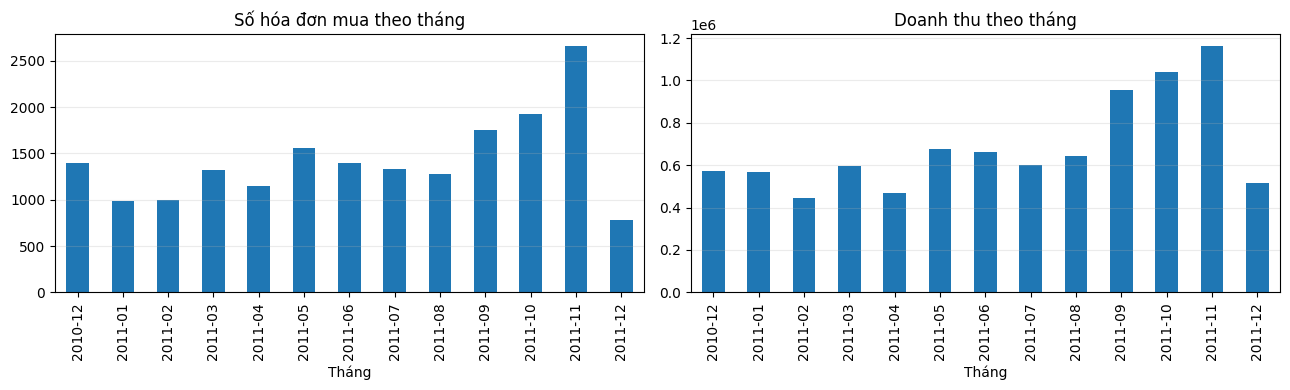

,count,mean,std,min,50%,75%,90%,95%,99%,max
frequency,4338.0,4.272015,7.697998,1.00,2.000000,5.000000,9.000000,13.000000,30.000000,209.000000
monetary,4338.0,2054.266460,8989.230441,3.75,674.485000,1661.740000,3646.531000,5841.843000,19880.995700,280206.020000
recency_at_dataset_end,4338.0,92.049317,100.013298,0.00,50.089931,141.730556,262.362986,311.039965,368.670049,373.122917


In [101]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly = invoices.assign(month=invoices["InvoiceDate"].dt.to_period("M")).groupby("month").agg(
    invoices=("InvoiceNo", "nunique"), revenue=("Monetary", "sum")
)
monthly["invoices"].plot(kind="bar", ax=axes[0], title="Số hóa đơn mua theo tháng")
monthly["revenue"].plot(kind="bar", ax=axes[1], title="Doanh thu theo tháng")
for ax in axes:
    ax.set_xlabel("Tháng")
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

customer_summary = invoices.groupby("CustomerID").agg(
    frequency=("InvoiceNo", "nunique"),
    monetary=("Monetary", "sum"),
    first_purchase=("InvoiceDate", "min"),
    last_purchase=("InvoiceDate", "max"),
)
customer_summary["recency_at_dataset_end"] = (
    invoices["InvoiceDate"].max() - customer_summary["last_purchase"]
).dt.total_seconds() / 86400

display(customer_summary[["frequency", "monetary", "recency_at_dataset_end"]].describe(percentiles=[.5, .75, .9, .95, .99]).T)

## 5. Xây dựng customer-invoice states và đặc trưng Dynamic RFM

Mỗi hóa đơn hợp lệ tạo một trạng thái khách hàng tại thời điểm hóa đơn. Lifetime/Rolling/Adaptive RFM chỉ dùng dữ liệu đến và bao gồm hóa đơn hiện tại; các mục tiêu được tạo từ hóa đơn kế tiếp trở đi.

In [102]:
snapshots = build_all_invoice_states(invoices, cfg)
snapshots.to_csv(RESULTS_DIR / "customer_invoice_states.csv.gz", index=False, compression="gzip")

print("Số customer-invoice states:", len(snapshots))
print("Số invoice identifiers toàn cục:", invoices["InvoiceNo"].nunique())
print("Số customer-invoice keys:", snapshots[["CustomerID", "current_invoice_no"]].drop_duplicates().shape[0])
print("Số khách hàng:", snapshots["CustomerID"].nunique())
print("Số ngày có invoice state:", snapshots["snapshot_date"].nunique())

# Mỗi customer-invoice chỉ xuất hiện một lần; một khách có thể có nhiều hóa đơn cùng ngày.
assert not snapshots.duplicated(["CustomerID", "current_invoice_no"]).any()
assert (pd.to_datetime(snapshots["state_timestamp"]) >= pd.to_datetime(snapshots["snapshot_date"])).all()

display(snapshots.head())
feature_cols = get_model_features(snapshots)
base_features = [c for c in cfg.base_features if c in feature_cols]
dynamic_features = feature_cols
assert not set(["target", "event_observed", "duration_days", "followup_days", "event_date"]).intersection(feature_cols)
assert all(pd.api.types.is_numeric_dtype(snapshots[c]) for c in feature_cols)

cycle_feature_cols = [c for c in dynamic_features if c.startswith(("ipi_", "log1p_ipi_", "cycle_", "last_ipi_", "adaptive_window_days"))]
temporal_prefixes = ("lag1_", "delta1_", "relative_delta1_", "lag4_", "delta4_", "slope4_")
temporal_feature_cols = [c for c in dynamic_features if c.startswith(temporal_prefixes) or c == "snapshot_gap_days"]
print("Lifetime RFM baseline:", base_features)
print("Tổng đặc trưng Dynamic RFM:", len(dynamic_features))
print("Đặc trưng chu kỳ mua hàng:", len(cycle_feature_cols))
print("Đặc trưng temporal:", len(temporal_feature_cols))
print("Ví dụ đặc trưng cycle:", cycle_feature_cols[:15])

Số customer-invoice states: 18532
Số invoice identifiers toàn cục: 18532
Số customer-invoice keys: 18532
Số khách hàng: 4338
Số ngày có invoice state: 305


,CustomerID,snapshot_date,state_timestamp,current_invoice_no,recency_days,frequency_lifetime,monetary_lifetime,quantity_lifetime,average_order_value,customer_age_days,...,relative_delta1_ipi_cv,lag4_ipi_cv,delta4_ipi_cv,slope4_ipi_cv_per_day,lag1_last_ipi_cycle_ratio,delta1_last_ipi_cycle_ratio,relative_delta1_last_ipi_cycle_ratio,lag4_last_ipi_cycle_ratio,delta4_last_ipi_cycle_ratio,slope4_last_ipi_cycle_ratio_per_day
0,12431,2010-12-01,2010-12-01 10:03:00,536389,365.0,1.0,358.25,107.0,358.25,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,12433,2010-12-01,2010-12-01 13:24:00,536532,365.0,1.0,1919.14,1852.0,1919.14,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,12583,2010-12-01,2010-12-01 08:45:00,536370,365.0,1.0,855.86,449.0,855.86,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,12662,2010-12-01,2010-12-01 13:04:00,536527,365.0,1.0,261.48,157.0,261.48,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,12748,2010-12-01,2010-12-01 12:48:00,536521,365.0,1.0,4.95,1.0,4.95,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Lifetime RFM baseline: ['log1p_recency_days', 'log1p_frequency_lifetime', 'log1p_monetary_lifetime']
Tổng đặc trưng Dynamic RFM: 160
Đặc trưng chu kỳ mua hàng: 14
Đặc trưng temporal: 73
Ví dụ đặc trưng cycle: ['ipi_median_days', 'ipi_std_days', 'ipi_count', 'ipi_cv', 'cycle_reliability', 'cycle_history_valid', 'cycle_reference_days', 'last_ipi_cycle_ratio', 'last_ipi_deviation_days', 'last_ipi_abs_deviation_days', 'last_ipi_longer_than_reference', 'adaptive_window_days', 'log1p_ipi_median_days', 'log1p_ipi_std_days']


## 6. Chia Train / Validation / Test theo đúng mốc thời gian của bài báo tham khảo

Bài báo LLM-Augmented không dùng một phép chia ngẫu nhiên 70/15/15. Bài báo dùng các mốc thời gian: Train trước 01/09/2011, Validation từ 01/09 đến 15/10/2011, Test từ 16/10 đến 09/12/2011. Notebook giữ nguyên các mốc này để so sánh cùng bối cảnh thời gian.


In [103]:
split = chronological_snapshot_split(
    snapshots, cfg, observed_end=invoices["InvoiceDate"].max()
)

split_rows = {
    "train": snapshots[snapshots["snapshot_date"].isin(split["train_dates"])].copy(),
    "validation": snapshots[snapshots["snapshot_date"].isin(split["validation_dates"])].copy(),
    "test": snapshots[snapshots["snapshot_date"].isin(split["test_dates"])].copy(),
}
follow_ends = {
    "train": split["train_end"],
    "validation": split["validation_end"],
    "test": split["test_end"],
}

PAPER_SPLIT_ROWS = {"train": 11439, "validation": 2656, "test": 4467}
split_summary = pd.DataFrame([
    {
        "partition": name,
        "n_customer_invoice_states": len(frame),
        "n_unique_global_invoice_ids": frame["current_invoice_no"].nunique(),
        "n_customers": frame["CustomerID"].nunique(),
        "share_of_states": len(frame) / len(snapshots),
        "paper_published_rows": PAPER_SPLIT_ROWS[name],
        "difference_vs_paper_rows": len(frame) - PAPER_SPLIT_ROWS[name],
        "n_snapshot_dates": frame["snapshot_date"].nunique(),
        "first_snapshot": frame["snapshot_date"].min(),
        "last_snapshot": frame["snapshot_date"].max(),
        "followup_censored_at": follow_ends[name],
    }
    for name, frame in split_rows.items()
])
display(split_summary)
split_summary.to_csv(RESULTS_DIR / "chronological_split_summary.csv", index=False)

assert split["train_dates"].max() < split["validation_dates"].min()
assert split["validation_dates"].max() < split["test_dates"].min()
assert pd.Timestamp(split["train_end"]) == pd.Timestamp("2011-09-01")
assert pd.Timestamp(split["validation_end"]) == pd.Timestamp("2011-10-16")
assert pd.Timestamp(split["test_dates"].min()) >= pd.Timestamp("2011-10-16")

if all(len(split_rows[k]) == PAPER_SPLIT_ROWS[k] for k in PAPER_SPLIT_ROWS):
    print("Số customer-invoice states trùng số hàng công bố trong bài báo theo từng partition.")
else:
    print("CẢNH BÁO: số hàng chưa khớp bài báo. Kiểm tra quy tắc làm sạch/aggregation và báo cáo số thực tế; không ép số dòng.")
print("Test chỉ có follow-up đến hết dữ liệu 09/12/2011; các state cuối kỳ sẽ bị right-censor trong survival analysis.")

,partition,n_customer_invoice_states,n_unique_global_invoice_ids,n_customers,share_of_states,paper_published_rows,difference_vs_paper_rows,n_snapshot_dates,first_snapshot,last_snapshot,followup_censored_at
0,train,11413,11413,3317,0.615854,11439,-26,219,2010-12-01,2011-08-31,2011-09-01
1,validation,2655,2655,1712,0.143266,2656,-1,38,2011-09-01,2011-10-14,2011-10-16
2,test,4464,4464,2277,0.240881,4467,-3,48,2011-10-16,2011-12-09,2011-12-10


CẢNH BÁO: số hàng chưa khớp bài báo. Kiểm tra quy tắc làm sạch/aggregation và báo cáo số thực tế; không ép số dòng.
Test chỉ có follow-up đến hết dữ liệu 09/12/2011; các state cuối kỳ sẽ bị right-censor trong survival analysis.


## 7. Gắn sự kiện mua tiếp theo và xử lý Right Censoring

In [104]:
observations = {}
binary_sets = {}
for name in ["train", "validation", "test"]:
    observations[name] = attach_time_to_event(
        split_rows[name], invoices, follow_ends[name], cfg.horizon_days
    )
    # Primary binary comparison: only a fully observed 30-day window is eligible.
    binary_sets[name] = make_horizon_label(
        observations[name], cfg.classification_horizon_days, require_full_followup=True
    )
    known = binary_sets[name]
    print(
        f"{name.upper()}: states={len(split_rows[name]):,}; "
        f"survival_rows={len(observations[name]):,}; "
        f"complete_{cfg.classification_horizon_days}d={len(known):,}; "
        f"positive_rate={known['target'].mean() if len(known) else np.nan:.4f}"
    )

censor_summary = pd.DataFrame([
    {
        "partition": name,
        "n_survival_observations": len(frame),
        "events_observed_within_90d": int(frame["event_observed"].sum()),
        "censored_or_no_event_within_90d": int((~frame["event_observed"]).sum()),
        "event_rate_within_90d": frame["event_observed"].mean(),
        "median_followup_days": frame["followup_days"].median(),
        "minimum_followup_days": frame["followup_days"].min(),
        "complete_30d_labels": len(binary_sets[name]),
        "positive_rate_30d": binary_sets[name]["target"].mean() if len(binary_sets[name]) else np.nan,
    }
    for name, frame in observations.items()
])
display(censor_summary)
censor_summary.to_csv(RESULTS_DIR / "censoring_and_label_audit.csv", index=False)

for part in ["train", "validation", "test"]:
    known = binary_sets[part]
    if known.empty or known["target"].nunique() < 2:
        raise RuntimeError(
            f"{part} 30-day complete-follow-up cohort is empty or has one class; "
            "inspect time cutoffs and data filtering."
        )
    assert (known["followup_days"] >= cfg.classification_horizon_days).all()

# Separate benchmark that reproduces the reference paper's observed-next-invoice label policy.
# IMPORTANT: this policy assigns 0 to a last observed invoice even when <30 days remain.
# It is used only to reproduce/diagnose the published protocol, never for the primary model.
paper_protocol_sets = {
    name: make_paper_protocol_labels(
        split_rows[name], invoices, horizon_days=cfg.classification_horizon_days
    )
    for name in ["train", "validation", "test"]
}
paper_label_audit = pd.DataFrame([
    {
        "partition": name,
        "n_rows": len(frame),
        "positive_count": int(frame["target"].sum()),
        "positive_rate": float(frame["target"].mean()),
        "paper_reference_positive_count": {"train": 5114, "validation": 1198, "test": 2044}[name],
        "difference_positive_count": int(frame["target"].sum()) - {"train": 5114, "validation": 1198, "test": 2044}[name],
        "n_last_states_assigned_zero": int(frame["next_invoice_date"].isna().sum()),
    }
    for name, frame in paper_protocol_sets.items()
])
display(paper_label_audit)
paper_label_audit.to_csv(RESULTS_DIR / "paper_protocol_label_audit.csv", index=False)

# Assert primary feature data do not contain outcome/label columns.
forbidden = {"target", "event_observed", "duration_days", "followup_days", "event_date", "next_invoice_date", "paper_time_to_next_days"}
assert not forbidden.intersection(dynamic_features)
print("Censoring checks passed. Primary metrics use complete 30-day cohorts; survival training retains partial follow-up.")

TRAIN: states=11,413; survival_rows=11,413; complete_30d=10,172; positive_rate=0.4431
VALIDATION: states=2,655; survival_rows=2,655; complete_30d=842; positive_rate=0.4810
TEST: states=4,464; survival_rows=4,464; complete_30d=1,783; positive_rate=0.5541


,partition,n_survival_observations,events_observed_within_90d,censored_or_no_event_within_90d,event_rate_within_90d,median_followup_days,minimum_followup_days,complete_30d_labels,positive_rate_30d
0,train,11413,7342,4071,0.643301,127.467361,0.280556,10172,0.443079
1,validation,2655,943,1712,0.355179,20.436111,1.275694,842,0.480998
2,test,4464,2187,2277,0.489919,24.476736,0.465278,1783,0.554122


,partition,n_rows,positive_count,positive_rate,paper_reference_positive_count,difference_positive_count,n_last_states_assigned_zero
0,train,11413,5088,0.445807,5114,-26,1365
1,validation,2655,1197,0.450847,1198,-1,696
2,test,4464,2041,0.457213,2044,-3,2277


Censoring checks passed. Primary metrics use complete 30-day cohorts; survival training retains partial follow-up.


## 8. Huấn luyện các baseline phân loại M1–M3

In [105]:
def _clean_X(frame, cols):
    return frame[cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)

def fit_binary_model(model, train_frame, feature_names):
    X_train = _clean_X(train_frame, feature_names)
    y_train = train_frame["target"].astype(int)
    if y_train.nunique() < 2:
        raise RuntimeError("Train chỉ có một lớp; hãy kiểm tra split/nhãn.")
    model.fit(X_train, y_train)
    return model

def make_prediction_frame(frame, probability, threshold):
    required_keys = ["CustomerID", "current_invoice_no", "state_timestamp", "snapshot_date", "target"]
    pred = frame[required_keys].copy()
    pred["probability"] = np.asarray(probability, dtype=float)
    pred["threshold"] = float(threshold)
    pred["prediction"] = (pred["probability"] >= float(threshold)).astype(int)
    assert not pred.duplicated(["CustomerID", "current_invoice_no"]).any()
    return pred.reset_index(drop=True)

all_metrics = []
top_fraction_records = []
all_predictions_seed42 = {}
all_predictions_by_seed = {}
feature_importance_records = []

for seed in SEEDS:
    print(f"\n========== SEED {seed} ==========")
    seed_predictions = {}
    models = make_binary_models(seed, cfg.n_estimators)
    for model_name, model in models.items():
        features = base_features if model_name == "M1_RFM_Logistic" else dynamic_features
        model = fit_binary_model(model, binary_sets["train"], features)
        val_probability = model.predict_proba(_clean_X(binary_sets["validation"], features))[:, 1]
        threshold = choose_threshold(binary_sets["validation"]["target"].to_numpy(), val_probability)
        test_probability = model.predict_proba(_clean_X(binary_sets["test"], features))[:, 1]
        result = binary_metrics(binary_sets["test"]["target"].to_numpy(), test_probability, threshold)
        result.update(top_fraction_metrics(binary_sets["test"]["target"].to_numpy(), test_probability, fraction=0.10))
        result.update({"model": model_name, "seed": seed, "metric_type": "binary_censor_aware_30d"})
        top_fraction_records.append({"model": model_name, "seed": seed, **top_fraction_metrics(binary_sets["test"]["target"].to_numpy(), test_probability, fraction=0.10)})
        all_metrics.append(result)

        pred = make_prediction_frame(binary_sets["test"], test_probability, threshold)
        seed_predictions[model_name] = pred
        if seed == 42:
            all_predictions_seed42[model_name] = pred

        estimator = model.named_steps["model"] if hasattr(model, "named_steps") else model
        if hasattr(estimator, "feature_importances_"):
            for feat, importance in zip(features, estimator.feature_importances_):
                feature_importance_records.append({
                    "seed": seed, "model": model_name,
                    "feature": feat, "importance": float(importance)
                })
    all_predictions_by_seed[seed] = seed_predictions

print("Đã huấn luyện xong M1–M3 trên censor-aware complete 30-day training cohort.")


========== SEED 42 ==========

========== SEED 43 ==========

========== SEED 44 ==========

========== SEED 45 ==========

========== SEED 46 ==========
Đã huấn luyện xong M1–M3 trên censor-aware complete 30-day training cohort.


## 9. Baseline Kaplan–Meier (M0) và mô hình đề xuất CA-PC-DRFM (M4)

**v4 update:** Bổ sung M5 Cox Proportional Hazards làm baseline Survival Analysis tiêu chuẩn; không phải phương pháp đề xuất.

In [106]:
horizon_metric_records = []
all_survival_predictions_seed42 = None
all_hazard_models_by_seed = {}
cox_coefficient_records = []

for seed in SEEDS:
    seed_predictions = all_predictions_by_seed.setdefault(seed, {})

    # M0: non-personalized Kaplan-Meier baseline from Train outcomes only.
    km_risk30 = kaplan_meier_purchase_probability(observations["train"], cfg.classification_horizon_days)
    km_val_prob = np.full(len(binary_sets["validation"]), km_risk30, dtype=float)
    km_threshold = choose_threshold(binary_sets["validation"]["target"].to_numpy(), km_val_prob)
    km_test_prob = np.full(len(binary_sets["test"]), km_risk30, dtype=float)
    km_result = binary_metrics(binary_sets["test"]["target"].to_numpy(), km_test_prob, km_threshold)
    km_result.update(top_fraction_metrics(binary_sets["test"]["target"].to_numpy(), km_test_prob, fraction=0.10))
    km_result.update({"model": "M0_KaplanMeier", "seed": seed, "metric_type": "binary_censor_aware_30d"})
    all_metrics.append(km_result)
    km_pred = make_prediction_frame(binary_sets["test"], km_test_prob, km_threshold)
    seed_predictions["M0_KaplanMeier"] = km_pred
    if seed == 42:
        all_predictions_seed42["M0_KaplanMeier"] = km_pred

    # M4: fit discrete-time hazard using all partially observed Train states.
    train_period = build_person_period(observations["train"], dynamic_features, cfg)
    hazard_features = dynamic_features + ["period_idx", "period_lower", "period_upper"]
    hazard_model = make_hazard_model(seed, cfg.n_estimators)
    X_period = _clean_X(train_period, hazard_features)
    y_period = train_period["hazard_event"].astype(int)
    if y_period.nunique() < 2:
        raise RuntimeError("Hazard Train chỉ có một lớp; kiểm tra dữ liệu/split.")
    hazard_model.fit(X_period, y_period)

    val30 = binary_sets["validation"]
    val_risk30 = predict_hazard_risk(
        hazard_model, val30, dynamic_features, cfg.interval_edges, cfg.classification_horizon_days
    )
    hazard_threshold = choose_threshold(val30["target"].to_numpy(), val_risk30)
    test30 = binary_sets["test"]
    test_risk30 = predict_hazard_risk(
        hazard_model, test30, dynamic_features, cfg.interval_edges, cfg.classification_horizon_days
    )
    hazard_result = binary_metrics(test30["target"].to_numpy(), test_risk30, hazard_threshold)
    hazard_result.update(top_fraction_metrics(test30["target"].to_numpy(), test_risk30, fraction=0.10))
    hazard_result.update({"model": "M4_CA_PC_DRFM_Hazard", "seed": seed, "metric_type": "binary_censor_aware_30d"})
    all_metrics.append(hazard_result)
    proposed_pred = make_prediction_frame(test30, test_risk30, hazard_threshold)
    seed_predictions["M4_CA_PC_DRFM_Hazard"] = proposed_pred
    if seed == 42:
        all_predictions_seed42["M4_CA_PC_DRFM_Hazard"] = proposed_pred

    # M4-CC: ablation/control trained only on Train states with complete 30-day follow-up.
    # It uses the same discrete hazard learner and same 30-day validation/test cohort.
    train_cc30 = observations["train"].loc[
        observations["train"]["followup_days"] >= cfg.classification_horizon_days
    ].copy()
    _original_duration_cc = train_cc30["duration_days"].astype(float).copy()
    train_cc30["event_observed"] = (
        train_cc30["event_observed"].astype(bool)
        & (_original_duration_cc <= cfg.classification_horizon_days)
    )
    train_cc30["duration_days"] = np.minimum(
        _original_duration_cc, float(cfg.classification_horizon_days)
    )
    train_cc30["followup_days"] = float(cfg.classification_horizon_days)
    train_period_cc = build_person_period(train_cc30, dynamic_features, cfg)
    hazard_model_cc = make_hazard_model(seed, cfg.n_estimators)
    X_period_cc = _clean_X(train_period_cc, hazard_features)
    y_period_cc = train_period_cc["hazard_event"].astype(int)
    if y_period_cc.nunique() < 2:
        raise RuntimeError("M4-CC Train chỉ có một lớp; kiểm tra cohort complete-case.")
    hazard_model_cc.fit(X_period_cc, y_period_cc)
    val_risk_cc = predict_hazard_risk(
        hazard_model_cc, val30, dynamic_features, cfg.interval_edges, cfg.classification_horizon_days
    )
    threshold_cc = choose_threshold(val30["target"].to_numpy(), val_risk_cc)
    test_risk_cc = predict_hazard_risk(
        hazard_model_cc, test30, dynamic_features, cfg.interval_edges, cfg.classification_horizon_days
    )
    cc_result = binary_metrics(test30["target"].to_numpy(), test_risk_cc, threshold_cc)
    cc_result.update(top_fraction_metrics(test30["target"].to_numpy(), test_risk_cc, fraction=0.10))
    cc_result.update({
        "model": "M4_CC_CompleteCase_Hazard", "seed": seed,
        "metric_type": "binary_censor_aware_30d",
        "n_train_complete_30d": int(len(train_cc30)),
    })
    all_metrics.append(cc_result)
    cc_pred = make_prediction_frame(test30, test_risk_cc, threshold_cc)
    seed_predictions["M4_CC_CompleteCase_Hazard"] = cc_pred
    if seed == 42:
        all_predictions_seed42["M4_CC_CompleteCase_Hazard"] = cc_pred

    # Horizon-specific classification metrics use only rows with a fully observed horizon.
    for horizon in cfg.interval_edges:
        val_h = make_horizon_label(observations["validation"], horizon, require_full_followup=True)
        test_h = make_horizon_label(observations["test"], horizon, require_full_followup=True)
        if (val_h.empty or test_h.empty or val_h["target"].nunique() < 2 or test_h["target"].nunique() < 2):
            print(f"Bỏ qua metric horizon={horizon}d: không đủ hai lớp với full follow-up ở Validation/Test.")
            continue
        val_p = predict_hazard_risk(hazard_model, val_h, dynamic_features, cfg.interval_edges, horizon)
        test_p = predict_hazard_risk(hazard_model, test_h, dynamic_features, cfg.interval_edges, horizon)
        threshold_h = choose_threshold(val_h["target"].to_numpy(), val_p)
        score = binary_metrics(test_h["target"].to_numpy(), test_p, threshold_h)
        score["brier_score"] = score.pop("brier_30d")
        score.update({"model": "M4_CA_PC_DRFM_Hazard", "seed": seed, "horizon_days": int(horizon)})
        horizon_metric_records.append(score)

    # C-index: choose one earliest Test state/customer and align event censoring to 45 days.
    test_one_per_customer = (
        observations["test"].sort_values(["CustomerID", "state_timestamp", "current_invoice_no"])
        .drop_duplicates("CustomerID", keep="first").reset_index(drop=True)
    )
    risk45_unique = predict_hazard_risk(
        hazard_model, test_one_per_customer, dynamic_features, cfg.interval_edges, 45
    )
    c_index45 = harrell_c_index_at_horizon(
        test_one_per_customer["duration_days"].to_numpy(dtype=float),
        test_one_per_customer["event_observed"].to_numpy(dtype=bool),
        risk45_unique,
        test_one_per_customer["CustomerID"].astype(str).to_numpy(),
        horizon_days=45,
        seed=seed,
    )
    all_metrics.append({
        "model": "M4_CA_PC_DRFM_Hazard", "seed": seed,
        "metric_type": "survival", "c_index_45d_first_state_per_customer": c_index45,
        "n_survival_test": int(len(observations["test"])),
        "n_unique_test_customers_for_cindex": int(len(test_one_per_customer)),
        "observed_event_rate_45d": float((
            observations["test"]["event_observed"]
            & (observations["test"]["duration_days"] <= 45)
        ).mean()),
    })


    # M5: penalized Cox Proportional Hazards baseline using the same right-censored Train spells.
    # This is a standard survival comparator; it is not part of the proposed M4 method.
    cox_features = select_cox_features(observations["train"])
    if len(cox_features) < 5:
        raise RuntimeError(f"Cox PH chỉ còn {len(cox_features)} đặc trưng hợp lệ; kiểm tra dữ liệu.")
    cox_model = CoxPHRiskModel(penalizer=0.05, max_iter=500)
    cox_model.fit(
        _clean_X(observations["train"], cox_features),
        observations["train"]["duration_days"].to_numpy(dtype=float),
        observations["train"]["event_observed"].to_numpy(dtype=bool),
    )
    cox_val_prob = cox_model.predict_risk(
        _clean_X(binary_sets["validation"], cox_features), cfg.classification_horizon_days
    )
    cox_threshold = choose_threshold(binary_sets["validation"]["target"].to_numpy(), cox_val_prob)
    cox_test_prob = cox_model.predict_risk(
        _clean_X(binary_sets["test"], cox_features), cfg.classification_horizon_days
    )
    cox_result = binary_metrics(binary_sets["test"]["target"].to_numpy(), cox_test_prob, cox_threshold)
    cox_result.update(top_fraction_metrics(binary_sets["test"]["target"].to_numpy(), cox_test_prob, fraction=0.10))
    cox_result.update({"model": "M5_CoxPH", "seed": seed, "metric_type": "binary_censor_aware_30d",
                       "cox_converged": bool(cox_model.converged_), "cox_optimization_message": cox_model.optimization_message_})
    all_metrics.append(cox_result)
    cox_pred = make_prediction_frame(binary_sets["test"], cox_test_prob, cox_threshold)
    seed_predictions["M5_CoxPH"] = cox_pred
    if seed == 42:
        all_predictions_seed42["M5_CoxPH"] = cox_pred
    for _row in cox_model.get_coefficients().to_dict("records"):
        cox_coefficient_records.append({"seed": seed, **_row})

    # Store both hazard learners to support a paper-label protocol evaluation later.
    all_hazard_models_by_seed[seed] = {
        "M4_CA_PC_DRFM_Hazard": hazard_model,
        "M4_CC_CompleteCase_Hazard": hazard_model_cc,
        "M5_CoxPH": cox_model,
    }

    # C-index for Cox is calculated on the same first-state-per-customer cohort and 45d horizon.
    cox_risk45_unique = cox_model.predict_risk(
        _clean_X(test_one_per_customer, cox_features), 45
    )
    cox_c_index45 = harrell_c_index_at_horizon(
        test_one_per_customer["duration_days"].to_numpy(dtype=float),
        test_one_per_customer["event_observed"].to_numpy(dtype=bool),
        cox_risk45_unique,
        test_one_per_customer["CustomerID"].astype(str).to_numpy(),
        horizon_days=45,
        seed=seed,
    )
    all_metrics.append({
        "model": "M5_CoxPH", "seed": seed, "metric_type": "survival",
        "c_index_45d_first_state_per_customer": cox_c_index45,
        "n_survival_test": int(len(observations["test"])),
        "n_unique_test_customers_for_cindex": int(len(test_one_per_customer)),
    })

    # Record Top-decile lift for M0/M4/M4-CC too; M1-M3 were recorded in the prior cell.
    for _name, _pred in [("M0_KaplanMeier", km_pred), ("M4_CA_PC_DRFM_Hazard", proposed_pred),
                         ("M4_CC_CompleteCase_Hazard", cc_pred), ("M5_CoxPH", cox_pred)]:
        top_fraction_records.append({"model": _name, "seed": seed,
            **top_fraction_metrics(_pred["target"].to_numpy(), _pred["probability"].to_numpy(), fraction=0.10)})

    if seed == 42:
        all_survival_predictions_seed42 = observations["test"][
            ["CustomerID", "current_invoice_no", "state_timestamp", "snapshot_date", "duration_days", "event_observed", "followup_days"]
        ].copy()
        for horizon in [7, 30, 45, 60, 90]:
            all_survival_predictions_seed42[f"risk_{horizon}d"] = predict_hazard_risk(
                hazard_model, observations["test"], dynamic_features, cfg.interval_edges, horizon
            )
        all_survival_predictions_seed42["risk_60d_90d_note"] = (
            "model extrapolation only where test follow-up is insufficient; do not claim empirically validated"
        )

    for model_name, fitted_model, features_for_model in [
        ("M4_CA_PC_DRFM_Hazard", hazard_model, hazard_features),
        ("M4_CC_CompleteCase_Hazard", hazard_model_cc, hazard_features),
    ]:
        if hasattr(fitted_model, "feature_importances_"):
            for feat, importance in zip(features_for_model, fitted_model.feature_importances_):
                feature_importance_records.append({
                    "seed": seed, "model": model_name,
                    "feature": feat, "importance": float(importance)
                })

    all_predictions_by_seed[seed] = seed_predictions

print("Đã hoàn tất M0, M4, M4-CC và baseline Cox PH (M5).")
cox_coefficients_frame = pd.DataFrame(cox_coefficient_records)
cox_coefficients_frame.to_csv(RESULTS_DIR / "cox_ph_coefficients_by_seed.csv", index=False)

Bỏ qua metric horizon=45d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=60d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=90d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=45d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=60d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=90d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=45d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=60d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=90d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=45d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=60d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric horizon=90d: không đủ hai lớp với full follow-up ở Validation/Test.
Bỏ qua metric ho

## 10. Tổng hợp kết quả và so sánh mô hình

In [107]:
metrics_frame = pd.DataFrame(all_metrics)
metrics_frame.to_csv(RESULTS_DIR / "metrics_by_seed.csv", index=False)

if horizon_metric_records:
    horizon_frame = pd.DataFrame(horizon_metric_records)
    horizon_frame.to_csv(RESULTS_DIR / "survival_horizon_metrics.csv", index=False)
    horizon_summary = horizon_frame.groupby("horizon_days")[
        ["roc_auc", "average_precision", "f1", "brier_score", "n_test"]
    ].agg(["mean", "std"])
    display(horizon_summary)
    horizon_summary.to_csv(RESULTS_DIR / "survival_horizon_metric_summary.csv")
else:
    horizon_frame = pd.DataFrame()

binary_frame = metrics_frame.loc[
    metrics_frame.get("metric_type", pd.Series(index=metrics_frame.index, dtype=object)).eq("binary_censor_aware_30d")
].copy()
metric_columns = ["roc_auc", "average_precision", "precision", "recall", "f1", "f1_at_0_5", "best_f1_test_oracle", "brier_30d", "precision_at_top_fraction", "recall_at_top_fraction", "lift_at_top_fraction"]
summary = binary_frame.groupby("model")[metric_columns].agg(["mean", "std"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index()

survival_rows = metrics_frame.loc[
    metrics_frame.get("metric_type", pd.Series(index=metrics_frame.index, dtype=object)).eq("survival")
]
if not survival_rows.empty:
    survival_summary = survival_rows.groupby("model")["c_index_45d_first_state_per_customer"].agg(["mean", "std"]).reset_index()
    survival_summary = survival_summary.rename(columns={
        "mean": "c_index_45d_mean", "std": "c_index_45d_std"
    })
    summary = summary.merge(survival_summary, on="model", how="left")

summary.to_csv(RESULTS_DIR / "metrics_summary.csv", index=False)
display(summary.sort_values("average_precision_mean", ascending=False))

# CRM-oriented top-decile ranking metrics (same 30d test cohort).
top_fraction_frame = pd.DataFrame(top_fraction_records)
top_fraction_frame.to_csv(RESULTS_DIR / "top_decile_metrics_by_seed.csv", index=False)
top_fraction_summary = top_fraction_frame.groupby("model")[
    ["precision_at_top_fraction", "recall_at_top_fraction", "lift_at_top_fraction"]
].agg(["mean", "std"])
display(top_fraction_summary)
top_fraction_summary.to_csv(RESULTS_DIR / "top_decile_metrics_summary.csv")

roc_auc           average_precision                  f1  \
                  mean       std              mean       std      mean   
horizon_days                                                             
7             0.781433  0.000219          0.638336  0.000602  0.553789   
14            0.787279  0.000863          0.728095  0.000567  0.619768   
21            0.795454  0.000477          0.788939  0.000512  0.701741   
30            0.796040  0.000827          0.846708  0.000386  0.735886   

                       brier_score            n_test       
                   std        mean       std    mean  std  
horizon_days                                               
7             0.005716    0.128630  0.000110  3918.0  0.0  
14            0.017291    0.170086  0.000283  3291.0  0.0  
21            0.006981    0.184198  0.000302  2655.0  0.0  
30            0.011956    0.184503  0.000548  1783.0  0.0

,model,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,...,brier_30d_mean,brier_30d_std,precision_at_top_fraction_mean,precision_at_top_fraction_std,recall_at_top_fraction_mean,recall_at_top_fraction_std,lift_at_top_fraction_mean,lift_at_top_fraction_std,c_index_45d_mean,c_index_45d_std
4,M4_CA_PC_DRFM_Hazard,0.796040,0.000827,0.846708,0.000386,0.791771,0.009700,0.688057,0.027648,0.735886,...,0.184503,0.000548,0.981006,0.003060,0.177733,0.000554,1.770377,0.005522,0.667785,0.001448
5,M4_CC_CompleteCase_Hazard,0.795210,0.001193,0.845365,0.000796,0.799095,0.015078,0.667206,0.035276,0.726482,...,0.187935,0.000700,0.983240,0.003950,0.178138,0.000716,1.774410,0.007129,NaN,NaN
6,M5_CoxPH,0.790099,0.000000,0.844311,0.000000,0.766345,0.000000,0.723684,0.000000,0.744404,...,0.183960,0.000000,0.988827,0.000000,0.179150,0.000000,1.784492,0.000000,0.664035,0.000000
3,M3_DynamicRFM_LGBM,0.791010,0.001261,0.843860,0.000937,0.768171,0.011060,0.711943,0.012634,0.738845,...,0.188351,0.000639,0.982123,0.002498,0.177935,0.000453,1.772394,0.004509,NaN,NaN
1,M1_RFM_Logistic,0.780848,0.000000,0.839591,0.000000,0.796178,0.000000,0.632591,0.000000,0.705020,...,0.192268,0.000000,0.994413,0.000000,0.180162,0.000000,1.794574,0.000000,NaN,NaN
2,M2_DynamicRFM_RF,0.778454,0.001889,0.832731,0.002153,0.785927,0.010648,0.641498,0.019008,0.706155,...,0.192453,0.000807,0.967598,0.004674,0.175304,0.000847,1.746181,0.008435,NaN,NaN
0,M0_KaplanMeier,0.500000,0.000000,0.554122,0.000000,0.554122,0.000000,1.000000,0.000000,0.713100,...,0.259989,0.000000,0.486034,0.000000,0.088057,0.000000,0.877123,0.000000,NaN,NaN


precision_at_top_fraction            \
                                               mean       std   
model                                                           
M0_KaplanMeier                             0.486034  0.000000   
M1_RFM_Logistic                            0.994413  0.000000   
M2_DynamicRFM_RF                           0.967598  0.004674   
M3_DynamicRFM_LGBM                         0.982123  0.002498   
M4_CA_PC_DRFM_Hazard                       0.981006  0.003060   
M4_CC_CompleteCase_Hazard                  0.983240  0.003950   
M5_CoxPH                                   0.988827  0.000000   

                          recall_at_top_fraction            \
                                            mean       std   
model                                                        
M0_KaplanMeier                          0.088057  0.000000   
M1_RFM_Logistic                         0.180162  0.000000   
M2_DynamicRFM_RF                        0.175304  0.000847   
M3_DynamicRFM_LGBM                      0.177935  0.000453   
M4_CA_PC_DRFM_Hazard                    0.177733  0.000554   
M4_CC_CompleteCase_Hazard               0.178138  0.000716   
M5_CoxPH                                0.179150  0.000000   

                          lift_at_top_fraction            
                                          mean       std  
model                                                     
M0_KaplanMeier                        0.877123  0.000000  
M1_RFM_Logistic                       1.794574  0.000000  
M2_DynamicRFM_RF                      1.746181  0.008435  
M3_DynamicRFM_LGBM                    1.772394  0.004509  
M4_CA_PC_DRFM_Hazard                  1.770377  0.005522  
M4_CC_CompleteCase_Hazard             1.774410  0.007129  
M5_CoxPH                              1.784492  0.000000

## 10.1. Benchmark theo đúng nhãn tham khảo và đối chiếu công bố

Phần này tái tạo **quy tắc nhãn quan sát** của bài báo: nếu không quan sát thấy hóa đơn tiếp theo trong toàn bộ file, state được gán 0. Đây không phải primary analysis vì các state cuối kỳ có thể chưa đủ 30 ngày follow-up. Phần này chỉ giúp kiểm tra split/label protocol và đặt kết quả local cạnh số công bố; feature engineering của nhóm không hoàn toàn giống tác giả nên không gọi là reproduction chính xác.

**v4 update:** M4 và M4-CC cũng được chấm trên cùng paper-label protocol (nhưng được train bằng survival likelihood). F1 threshold được tách khỏi best F1 oracle trên Test; kết quả oracle chỉ mang tính mô tả.

In [108]:
paper_metrics = []
paper_predictions_seed42 = {}
for seed in SEEDS:
    paper_models = make_binary_models(seed, cfg.n_estimators)
    train_paper = paper_protocol_sets["train"]
    val_paper = paper_protocol_sets["validation"]
    test_paper = paper_protocol_sets["test"]

    # M1/M3 are fitted using the reference paper's observed-next-purchase label rule.
    for model_name in ["M1_RFM_Logistic", "M3_DynamicRFM_LGBM"]:
        model = paper_models[model_name]
        cols = base_features if model_name == "M1_RFM_Logistic" else dynamic_features
        model.fit(_clean_X(train_paper, cols), train_paper["target"].astype(int))
        val_prob = model.predict_proba(_clean_X(val_paper, cols))[:, 1]
        threshold = choose_threshold(val_paper["target"].to_numpy(dtype=int), val_prob)
        test_prob = model.predict_proba(_clean_X(test_paper, cols))[:, 1]
        score = binary_metrics(test_paper["target"].to_numpy(dtype=int), test_prob, threshold)
        score.update({"model": f"PaperPolicy_{model_name}", "seed": seed,
                      "protocol": "observed_next_invoice_within_30d"})
        paper_metrics.append(score)
        if seed == 42:
            paper_predictions_seed42[model_name] = make_prediction_frame(test_paper, test_prob, threshold)

    # M5 Cox PH is also evaluated on the paper-label outcome cohort after censor-aware fitting.
    cox_model_paper = all_hazard_models_by_seed[seed]["M5_CoxPH"]
    cox_features_paper = select_cox_features(observations["train"])
    val_prob_cox_paper = cox_model_paper.predict_risk(_clean_X(val_paper, cox_features_paper), cfg.classification_horizon_days)
    threshold_cox_paper = choose_threshold(val_paper["target"].to_numpy(dtype=int), val_prob_cox_paper)
    test_prob_cox_paper = cox_model_paper.predict_risk(_clean_X(test_paper, cox_features_paper), cfg.classification_horizon_days)
    score_cox_paper = binary_metrics(test_paper["target"].to_numpy(dtype=int), test_prob_cox_paper, threshold_cox_paper)
    score_cox_paper.update({"model": "PaperPolicy_M5_CoxPH", "seed": seed,
                            "protocol": "paper_labels_evaluated_after_censor_aware_training"})
    paper_metrics.append(score_cox_paper)
    if seed == 42:
        paper_predictions_seed42["M5_CoxPH"] = make_prediction_frame(test_paper, test_prob_cox_paper, threshold_cox_paper)

    # M4/M4-CC are trained with censor-aware survival likelihood, then evaluated
    # under the separate reference paper label policy for an aligned outcome check.
    stored = all_hazard_models_by_seed[seed]
    for model_name in ["M4_CA_PC_DRFM_Hazard", "M4_CC_CompleteCase_Hazard"]:
        model = stored[model_name]
        val_prob = predict_hazard_risk(model, val_paper, dynamic_features, cfg.interval_edges, cfg.classification_horizon_days)
        threshold = choose_threshold(val_paper["target"].to_numpy(dtype=int), val_prob)
        test_prob = predict_hazard_risk(model, test_paper, dynamic_features, cfg.interval_edges, cfg.classification_horizon_days)
        score = binary_metrics(test_paper["target"].to_numpy(dtype=int), test_prob, threshold)
        score.update({"model": f"PaperPolicy_{model_name}", "seed": seed,
                      "protocol": "paper_labels_evaluated_after_censor_aware_training"})
        paper_metrics.append(score)
        if seed == 42:
            paper_predictions_seed42[model_name] = make_prediction_frame(test_paper, test_prob, threshold)

paper_metrics_frame = pd.DataFrame(paper_metrics)
paper_metrics_frame.to_csv(RESULTS_DIR / "paper_protocol_metrics_by_seed.csv", index=False)
paper_summary = paper_metrics_frame.groupby("model")[
    ["roc_auc", "average_precision", "f1", "f1_at_0_5", "best_f1_test_oracle", "brier_30d", "positive_rate", "n_test"]
].agg(["mean", "std"])
display(paper_summary)
paper_summary.to_csv(RESULTS_DIR / "paper_protocol_metric_summary.csv")

# Correctly distinguish the paper's F1 at its selected/operating threshold from its
# best possible Test-threshold F1. Do not place them in one generic F1 column.
published_reference_metrics = pd.DataFrame([
    {"model": "RFM Logistic (published)", "roc_auc": 0.740, "average_precision": 0.734,
     "f1_at_published_threshold": 0.607, "best_f1_test_oracle": 0.665, "brier_30d": 0.233},
    {"model": "Engineered LightGBM (published)", "roc_auc": 0.719, "average_precision": 0.713,
     "f1_at_published_threshold": 0.560, "best_f1_test_oracle": 0.658, "brier_30d": 0.267},
    {"model": "Persona + LightGBM (published)", "roc_auc": 0.724, "average_precision": 0.718,
     "f1_at_published_threshold": 0.524, "best_f1_test_oracle": 0.662, "brier_30d": 0.259},
    {"model": "Transformer (published)", "roc_auc": 0.588, "average_precision": 0.522,
     "f1_at_published_threshold": 0.388, "best_f1_test_oracle": 0.638, "brier_30d": 0.243},
])
published_reference_metrics.to_csv(RESULTS_DIR / "published_reference_metrics.csv", index=False)

paper_count_comparison = pd.DataFrame([
    {
        "partition": part,
        "local_states": len(paper_protocol_sets[part]),
        "local_positives": int(paper_protocol_sets[part]["target"].sum()),
        "local_positive_rate": float(paper_protocol_sets[part]["target"].mean()),
        "paper_states": {"train": 11439, "validation": 2656, "test": 4467}[part],
        "paper_positives": {"train": 5114, "validation": 1198, "test": 2044}[part],
    }
    for part in ["train", "validation", "test"]
])
display(paper_count_comparison)
paper_count_comparison.to_csv(RESULTS_DIR / "paper_split_and_label_count_comparison.csv", index=False)

print("Đây là benchmark theo label policy công bố, không dùng để kết luận chất lượng censor-aware model.")
print("Do feature set/siêu tham số có thể khác bài báo, không gọi chênh lệch AUC local là vượt trội trực tiếp.")

roc_auc           average_precision  \
                                           mean       std              mean   
model                                                                         
PaperPolicy_M1_RFM_Logistic            0.740348  0.000000          0.733749   
PaperPolicy_M3_DynamicRFM_LGBM         0.741413  0.001050          0.735089   
PaperPolicy_M4_CA_PC_DRFM_Hazard       0.743624  0.001019          0.735823   
PaperPolicy_M4_CC_CompleteCase_Hazard  0.745022  0.001035          0.734088   
PaperPolicy_M5_CoxPH                   0.738127  0.000000          0.726619   

                                                       f1           f1_at_0_5  \
                                            std      mean       std      mean   
model                                                                           
PaperPolicy_M1_RFM_Logistic            0.000000  0.657096  0.000000  0.660884   
PaperPolicy_M3_DynamicRFM_LGBM         0.000694  0.663791  0.003668  0.659748   
PaperPolicy_M4_CA_PC_DRFM_Hazard       0.001291  0.660629  0.001443  0.661146   
PaperPolicy_M4_CC_CompleteCase_Hazard  0.001244  0.663624  0.001557  0.658340   
PaperPolicy_M5_CoxPH                   0.000000  0.668350  0.000000  0.667927   

                                                best_f1_test_oracle            \
                                            std                mean       std   
model                                                                           
PaperPolicy_M1_RFM_Logistic            0.000000            0.664979  0.000000   
PaperPolicy_M3_DynamicRFM_LGBM         0.003166            0.670227  0.002457   
PaperPolicy_M4_CA_PC_DRFM_Hazard       0.001967            0.671264  0.000774   
PaperPolicy_M4_CC_CompleteCase_Hazard  0.001244            0.672412  0.000968   
PaperPolicy_M5_CoxPH                   0.000000            0.670535  0.000000   

                                      brier_30d           positive_rate       \
                                           mean       std          mean  std   
model                                                                          
PaperPolicy_M1_RFM_Logistic            0.233330  0.000000      0.457213  0.0   
PaperPolicy_M3_DynamicRFM_LGBM         0.211571  0.000609      0.457213  0.0   
PaperPolicy_M4_CA_PC_DRFM_Hazard       0.214426  0.000666      0.457213  0.0   
PaperPolicy_M4_CC_CompleteCase_Hazard  0.210009  0.000972      0.457213  0.0   
PaperPolicy_M5_CoxPH                   0.231026  0.000000      0.457213  0.0   

                                       n_test       
                                         mean  std  
model                                               
PaperPolicy_M1_RFM_Logistic            4464.0  0.0  
PaperPolicy_M3_DynamicRFM_LGBM         4464.0  0.0  
PaperPolicy_M4_CA_PC_DRFM_Hazard       4464.0  0.0  
PaperPolicy_M4_CC_CompleteCase_Hazard  4464.0  0.0  
PaperPolicy_M5_CoxPH                   4464.0  0.0

,partition,local_states,local_positives,local_positive_rate,paper_states,paper_positives
0,train,11413,5088,0.445807,11439,5114
1,validation,2655,1197,0.450847,2656,1198
2,test,4464,2041,0.457213,4467,2044


Đây là benchmark theo label policy công bố, không dùng để kết luận chất lượng censor-aware model.
Do feature set/siêu tham số có thể khác bài báo, không gọi chênh lệch AUC local là vượt trội trực tiếp.


## 10.2. Đánh giá bổ sung ở cấp khách hàng

Invoice-state metric có thể để khách hàng mua nhiều lần đóng góp nhiều hàng hơn. Vì vậy, báo cáo thêm (i) metric có tổng trọng số mỗi khách hàng bằng nhau và (ii) metric trên state Test đầu tiên của mỗi khách hàng. Đây là sensitivity analysis, không thay thế metric invoice-state chính.

In [109]:
customer_balanced_records = []
first_state_records = []
for seed, model_predictions in all_predictions_by_seed.items():
    for model_name, pred in model_predictions.items():
        customer_balanced = customer_balanced_binary_metrics(
            pred["target"].to_numpy(dtype=int),
            pred["probability"].to_numpy(dtype=float),
            float(pred["threshold"].iloc[0]),
            pred["CustomerID"].astype(str).to_numpy(),
        )
        customer_balanced.update({"seed": seed, "model": model_name})
        customer_balanced_records.append(customer_balanced)

        first_per_customer = (
            pred.sort_values(["CustomerID", "state_timestamp", "current_invoice_no"])
            .drop_duplicates("CustomerID", keep="first")
        )
        first_metrics = binary_metrics(
            first_per_customer["target"].to_numpy(dtype=int),
            first_per_customer["probability"].to_numpy(dtype=float),
            float(first_per_customer["threshold"].iloc[0]),
        )
        first_metrics.update({
            "seed": seed, "model": model_name,
            "n_customers": int(first_per_customer["CustomerID"].nunique()),
        })
        first_state_records.append(first_metrics)

customer_balanced_frame = pd.DataFrame(customer_balanced_records)
first_state_frame = pd.DataFrame(first_state_records)
customer_balanced_frame.to_csv(RESULTS_DIR / "customer_balanced_metrics_by_seed.csv", index=False)
first_state_frame.to_csv(RESULTS_DIR / "first_test_state_per_customer_metrics.csv", index=False)

display(customer_balanced_frame.groupby("model")[
    ["roc_auc", "average_precision", "f1", "brier"]
].agg(["mean", "std"]))
display(first_state_frame.groupby("model")[
    ["roc_auc", "average_precision", "f1", "brier_30d"]
].agg(["mean", "std"]))

roc_auc           average_precision            \
                               mean       std              mean       std   
model                                                                       
M0_KaplanMeier             0.500000  0.000000          0.428582  0.000000   
M1_RFM_Logistic            0.734532  0.000000          0.714352  0.000000   
M2_DynamicRFM_RF           0.727403  0.002222          0.694522  0.002360   
M3_DynamicRFM_LGBM         0.745216  0.001399          0.711934  0.001421   
M4_CA_PC_DRFM_Hazard       0.749085  0.001161          0.714918  0.000506   
M4_CC_CompleteCase_Hazard  0.750278  0.001636          0.713856  0.001487   
M5_CoxPH                   0.745278  0.000000          0.719943  0.000000   

                                 f1               brier            
                               mean       std      mean       std  
model                                                              
M0_KaplanMeier             0.600011  0.000000  0.245041  0.000000  
M1_RFM_Logistic            0.601334  0.000000  0.214813  0.000000  
M2_DynamicRFM_RF           0.586702  0.009785  0.203337  0.000702  
M3_DynamicRFM_LGBM         0.638825  0.003662  0.198485  0.000517  
M4_CA_PC_DRFM_Hazard       0.627130  0.017085  0.197148  0.000261  
M4_CC_CompleteCase_Hazard  0.618770  0.022914  0.197981  0.000596  
M5_CoxPH                   0.649707  0.000000  0.199682  0.000000

roc_auc           average_precision            \
                               mean       std              mean       std   
model                                                                       
M0_KaplanMeier             0.500000  0.000000          0.467854  0.000000   
M1_RFM_Logistic            0.732480  0.000000          0.747445  0.000000   
M2_DynamicRFM_RF           0.723084  0.002386          0.725606  0.001869   
M3_DynamicRFM_LGBM         0.736161  0.001300          0.737323  0.001111   
M4_CA_PC_DRFM_Hazard       0.743369  0.001478          0.742894  0.000710   
M4_CC_CompleteCase_Hazard  0.743702  0.002028          0.741822  0.001594   
M5_CoxPH                   0.739170  0.000000          0.748240  0.000000   

                                 f1           brier_30d            
                               mean       std      mean       std  
model                                                              
M0_KaplanMeier             0.637467  0.000000  0.249717  0.000000  
M1_RFM_Logistic            0.605341  0.000000  0.210416  0.000000  
M2_DynamicRFM_RF           0.577894  0.011603  0.211101  0.000870  
M3_DynamicRFM_LGBM         0.631219  0.004755  0.209317  0.000548  
M4_CA_PC_DRFM_Hazard       0.617935  0.023216  0.205260  0.000684  
M4_CC_CompleteCase_Hazard  0.606820  0.027848  0.208075  0.000909  
M5_CoxPH                   0.652803  0.000000  0.201989  0.000000

## 11. Ablation Study và phân tích theo nhóm chu kỳ mua hàng

Ablation sử dụng cùng Train/Validation/Test, cùng censoring protocol và cùng horizon 30 ngày; chỉ thay đổi nhóm đặc trưng. A1–A5 giúp kiểm tra lần lượt đóng góp của Dynamic RFM, IPI, chu kỳ cá nhân có shrinkage và temporal lags. M4-CC ở trên là control riêng cho cách dùng dữ liệu censored.

Ablation seed=42
Ablation seed=43
Ablation seed=44
Ablation seed=45
Ablation seed=46


average_precision             roc_auc  \
                                              mean       std      mean   
ablation                                                                 
A1_Lifetime_RFM                           0.846253  0.000245  0.792159   
A2_Dynamic_RFM_Core                       0.846608  0.000423  0.793225   
A3_Dynamic_RFM_plus_raw_IPI               0.847331  0.000650  0.794661   
A4_plus_shrunk_personal_cycle             0.847645  0.000856  0.794285   
A5_full_CA_PC_DRFM_plus_temporal          0.846708  0.000386  0.796040   

                                                  f1           brier_30d  \
                                       std      mean       std      mean   
ablation                                                                   
A1_Lifetime_RFM                   0.000473  0.741831  0.013259  0.184749   
A2_Dynamic_RFM_Core               0.000551  0.722643  0.013225  0.183540   
A3_Dynamic_RFM_plus_raw_IPI       0.000592  0.723546  0.019946  0.184082   
A4_plus_shrunk_personal_cycle     0.001063  0.731179  0.014690  0.184554   
A5_full_CA_PC_DRFM_plus_temporal  0.000827  0.735886  0.011956  0.184503   

                                            
                                       std  
ablation                                    
A1_Lifetime_RFM                   0.000239  
A2_Dynamic_RFM_Core               0.000258  
A3_Dynamic_RFM_plus_raw_IPI       0.000451  
A4_plus_shrunk_personal_cycle     0.000414  
A5_full_CA_PC_DRFM_plus_temporal  0.000548

,model,group_type,group,n_rows,n_customers,positive_rate,average_precision,roc_auc,brier_score
0,M3_DynamicRFM_LGBM,cycle_status,Last_completed_IPI_longer_than_reference,532,522,0.541353,0.783709,0.743767,0.209779
1,M3_DynamicRFM_LGBM,cycle_status,Last_completed_IPI_within_reference,1251,906,0.559552,0.864412,0.810725,0.178528
2,M3_DynamicRFM_LGBM,cycle_regularity,Insufficient_IPI_history,533,502,0.309568,0.434676,0.610977,0.209094
3,M3_DynamicRFM_LGBM,cycle_regularity,More_irregular,1189,775,0.674516,0.891003,0.787415,0.178110
4,M3_DynamicRFM_LGBM,cycle_regularity,More_regular,61,61,0.344262,0.582567,0.772619,0.192141
5,M4_CA_PC_DRFM_Hazard,cycle_status,Last_completed_IPI_longer_than_reference,532,522,0.541353,0.791288,0.753785,0.203502
6,M4_CA_PC_DRFM_Hazard,cycle_status,Last_completed_IPI_within_reference,1251,906,0.559552,0.866105,0.812851,0.176226
7,M4_CA_PC_DRFM_Hazard,cycle_regularity,Insufficient_IPI_history,533,502,0.309568,0.436771,0.612558,0.209490
8,M4_CA_PC_DRFM_Hazard,cycle_regularity,More_irregular,1189,775,0.674516,0.893792,0.793675,0.172306
9,M4_CA_PC_DRFM_Hazard,cycle_regularity,More_regular,61,61,0.344262,0.573330,0.757143,0.199864


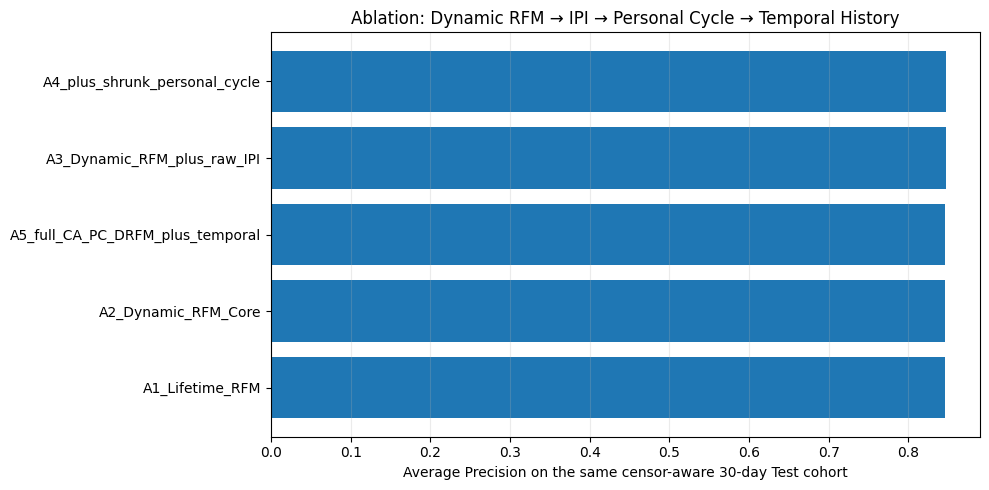

In [110]:
# Các nhóm đặc trưng được tách riêng để tránh gộp IPI thô và cycle-state vào cùng một ablation.
lag_prefixes = ("lag1_", "delta1_", "relative_delta1_", "lag4_", "delta4_", "slope4_")
raw_ipi_cols = [c for c in dynamic_features if c.startswith(("ipi_", "log1p_ipi_"))]
personal_cycle_cols = [c for c in dynamic_features if c.startswith(("cycle_", "last_ipi_")) or c == "adaptive_window_days"]
temporal_cols = [c for c in dynamic_features if c.startswith(lag_prefixes) or c == "snapshot_gap_days"]
excluded = set(raw_ipi_cols + personal_cycle_cols + temporal_cols)
core_cols = [c for c in dynamic_features if c not in excluded]

ablation_feature_sets = {
    "A1_Lifetime_RFM": base_features,
    "A2_Dynamic_RFM_Core": core_cols,
    "A3_Dynamic_RFM_plus_raw_IPI": core_cols + raw_ipi_cols,
    "A4_plus_shrunk_personal_cycle": core_cols + raw_ipi_cols + personal_cycle_cols,
    "A5_full_CA_PC_DRFM_plus_temporal": dynamic_features,
}

ablation_records = []
for seed in SEEDS:
    print(f"Ablation seed={seed}")
    for ablation_name, cols in ablation_feature_sets.items():
        cols = [c for c in cols if c in observations["train"].columns]
        pp_train = build_person_period(observations["train"], cols, cfg)
        model = make_hazard_model(seed, cfg.n_estimators)
        hazard_cols = cols + ["period_idx", "period_lower", "period_upper"]
        model.fit(_clean_X(pp_train, hazard_cols), pp_train["hazard_event"].astype(int))
        val_frame = binary_sets["validation"]
        test_frame = binary_sets["test"]
        val_prob = predict_hazard_risk(model, val_frame, cols, cfg.interval_edges, cfg.classification_horizon_days)
        test_prob = predict_hazard_risk(model, test_frame, cols, cfg.interval_edges, cfg.classification_horizon_days)
        threshold = choose_threshold(val_frame["target"].to_numpy(dtype=int), val_prob)
        score = binary_metrics(test_frame["target"].to_numpy(dtype=int), test_prob, threshold)
        score.update({"ablation": ablation_name, "seed": seed, "n_features": len(cols)})
        ablation_records.append(score)

ablation_frame = pd.DataFrame(ablation_records)
ablation_frame.to_csv(RESULTS_DIR / "hazard_ablation_metrics.csv", index=False)
ablation_summary = ablation_frame.groupby("ablation")[
    ["average_precision", "roc_auc", "f1", "brier_30d"]
].agg(["mean", "std"])
display(ablation_summary)
ablation_summary.to_csv(RESULTS_DIR / "hazard_ablation_summary.csv")

# Group-wise diagnostic: does personal cycle representation behave differently for regular/irregular buyers?
if all(col in binary_sets["test"].columns for col in ["last_ipi_cycle_ratio", "ipi_cv", "ipi_count"]):
    group_base = binary_sets["test"][
        ["CustomerID", "current_invoice_no", "state_timestamp", "snapshot_date", "target", "last_ipi_cycle_ratio", "ipi_cv", "ipi_count"]
    ].copy()
    train_cv_median = observations["train"]["ipi_cv"].replace([np.inf, -np.inf], np.nan).median()
    group_base["cycle_status"] = np.where(group_base["last_ipi_cycle_ratio"] > 1.0, "Last_completed_IPI_longer_than_reference", "Last_completed_IPI_within_reference")
    group_base["cycle_regularity"] = np.where(
        group_base["ipi_count"] < 2, "Insufficient_IPI_history",
        np.where(group_base["ipi_cv"] <= train_cv_median, "More_regular", "More_irregular")
    )
    subgroup_records = []
    for model_name in ["M3_DynamicRFM_LGBM", "M4_CA_PC_DRFM_Hazard", "M4_CC_CompleteCase_Hazard"]:
        pred = all_predictions_seed42.get(model_name)
        if pred is None:
            continue
        merged = group_base.merge(
            pred[["CustomerID", "current_invoice_no", "probability"]],
            on=["CustomerID", "current_invoice_no"], how="inner", validate="one_to_one"
        )
        for group_col in ["cycle_status", "cycle_regularity"]:
            for group_value, part in merged.groupby(group_col):
                y = part["target"].to_numpy(dtype=int)
                p = part["probability"].to_numpy(dtype=float)
                subgroup_records.append({
                    "model": model_name, "group_type": group_col, "group": group_value,
                    "n_rows": len(part), "n_customers": part["CustomerID"].nunique(),
                    "positive_rate": float(y.mean()),
                    "average_precision": average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan,
                    "roc_auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
                    "brier_score": brier_score_loss(y, p),
                })
    subgroup_frame = pd.DataFrame(subgroup_records)
    subgroup_frame.to_csv(RESULTS_DIR / "test_metrics_by_customer_cycle_group.csv", index=False)
    display(subgroup_frame)

fig, ax = plt.subplots(figsize=(10, 5))
plot_ablation = ablation_frame.groupby("ablation")["average_precision"].mean().sort_values()
ax.barh(plot_ablation.index, plot_ablation.values)
ax.set_xlabel("Average Precision on the same censor-aware 30-day Test cohort")
ax.set_title("Ablation: Dynamic RFM → IPI → Personal Cycle → Temporal History")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "hazard_ablation_average_precision.png", dpi=180, bbox_inches="tight")
plt.show()

## 12. Kiểm định thống kê và Customer-Level Bootstrap

So sánh ghép cặp giữa M4 với M3 (cùng tập Test) và M4 với M4-CC (cùng kiến trúc nhưng khác cách xử lý censoring). Bootstrap lấy mẫu theo CustomerID, giữ nguyên toàn bộ invoice states của khách được lấy mẫu.

**v4:** Bổ sung M5 Cox PH làm survival baseline. So sánh M4–M5 dùng cùng cohort và paired customer-cluster bootstrap; Cox PH được fit tất định nên độ lệch chuẩn theo seed có thể bằng 0, không nên diễn giải thành độ bất định dữ liệu.

In [111]:
paired_test_frames = []
for comparator in ["M3_DynamicRFM_LGBM", "M4_CC_CompleteCase_Hazard", "M5_CoxPH"]:
    part = paired_seed_tests(
        binary_frame,
        proposed="M4_CA_PC_DRFM_Hazard",
        comparator=comparator,
    )
    if not part.empty:
        paired_test_frames.append(part)
paired_tests = pd.concat(paired_test_frames, ignore_index=True) if paired_test_frames else pd.DataFrame()
paired_tests.to_csv(RESULTS_DIR / "paired_seed_tests.csv", index=False)
display(paired_tests)
print("Lưu ý: paired tests qua 5 seed là phân tích độ nhạy thuật toán; suy luận chính dựa trên customer-cluster bootstrap CI.")

bootstrap_ap_records = []
bootstrap_metric_frames = []
for comparator in ["M3_DynamicRFM_LGBM", "M4_CC_CompleteCase_Hazard", "M5_CoxPH"]:
    ap_result = customer_bootstrap_delta_ap_multi(
        all_predictions_by_seed,
        proposed_name="M4_CA_PC_DRFM_Hazard",
        comparator_name=comparator,
        repeats=cfg.bootstrap_repeats,
        seed=cfg.bootstrap_seed,
    )
    bootstrap_ap_records.append(ap_result)
    metric_result = customer_cluster_bootstrap_metrics_multi(
        all_predictions_by_seed,
        proposed_name="M4_CA_PC_DRFM_Hazard",
        comparator_name=comparator,
        repeats=cfg.bootstrap_repeats,
        seed=cfg.bootstrap_seed,
    )
    metric_result["comparison"] = f"M4 vs {comparator}"
    bootstrap_metric_frames.append(metric_result)

bootstrap_ap_frame = pd.DataFrame(bootstrap_ap_records)
bootstrap_ap_frame.to_csv(RESULTS_DIR / "customer_bootstrap_comparison.csv", index=False)
bootstrap_metrics_frame = pd.concat(bootstrap_metric_frames, ignore_index=True) if bootstrap_metric_frames else pd.DataFrame()
bootstrap_metrics_frame.to_csv(RESULTS_DIR / "customer_cluster_bootstrap_metrics.csv", index=False)
display(bootstrap_ap_frame)
display(bootstrap_metrics_frame)

# Kept for plotting cell compatibility: primary reference is M4 vs M3.
bootstrap_result = next((x for x in bootstrap_ap_records if x["comparator"] == "M3_DynamicRFM_LGBM"), None)

,metric,proposed,comparator,n_paired_seeds,mean_delta_proposed_minus_comparator,paired_t_p_value,wilcoxon_p_value,paired_t_holm_p_value,wilcoxon_holm_p_value
0,roc_auc,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,0.005030,0.002371,0.0625,0.007113,0.2500
1,average_precision,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,0.002848,0.004295,0.0625,0.008589,0.2500
2,f1,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,-0.002959,0.656032,1.0000,0.656032,1.0000
3,brier_30d,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,-0.003849,0.000703,0.0625,0.002813,0.2500
4,roc_auc,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,0.000830,0.085720,0.0625,0.171440,0.2500
5,average_precision,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,0.001343,0.004218,0.0625,0.012654,0.2500
6,f1,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,0.009404,0.422051,0.4375,0.422051,0.4375
7,brier_30d,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,-0.003432,0.000068,0.0625,0.000274,0.2500
8,roc_auc,M4_CA_PC_DRFM_Hazard,M5_CoxPH,5,0.005941,0.000088,0.0625,0.000351,0.2500
9,average_precision,M4_CA_PC_DRFM_Hazard,M5_CoxPH,5,0.002397,0.000156,0.0625,0.000469,0.2500


Lưu ý: paired tests qua 5 seed là phân tích độ nhạy thuật toán; suy luận chính dựa trên customer-cluster bootstrap CI.


,proposed,comparator,n_seeds,seeds,n_test_rows,n_test_customers,delta_average_precision_mean,ci95_lower,ci95_upper,probability_delta_positive,bootstrap_valid_repeats
0,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,"42,43,44,45,46",1783,1291,0.002865,-0.001589,0.007531,0.900,1000
1,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,"42,43,44,45,46",1783,1291,0.001331,-0.001880,0.004658,0.804,1000
2,M4_CA_PC_DRFM_Hazard,M5_CoxPH,5,"42,43,44,45,46",1783,1291,0.002628,-0.003578,0.008930,0.813,1000


,metric,proposed,comparator,n_seeds,n_test_customers,delta_mean,ci95_lower,ci95_upper,probability_delta_positive,delta_orientation,bootstrap_valid_repeats,comparison
0,average_precision,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,1291,0.002865,-0.001589,0.007531,0.900,positive means proposed model is better,1000,M4 vs M3_DynamicRFM_LGBM
1,roc_auc,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,1291,0.004976,-0.001729,0.011867,0.918,positive means proposed model is better,1000,M4 vs M3_DynamicRFM_LGBM
2,f1,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,1291,-0.002989,-0.012542,0.006455,0.279,positive means proposed model is better,1000,M4 vs M3_DynamicRFM_LGBM
3,brier,M4_CA_PC_DRFM_Hazard,M3_DynamicRFM_LGBM,5,1291,0.003872,0.001180,0.006568,0.999,positive means proposed model is better,1000,M4 vs M3_DynamicRFM_LGBM
4,average_precision,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,1291,0.001331,-0.001880,0.004658,0.804,positive means proposed model is better,1000,M4 vs M4_CC_CompleteCase_Hazard
5,roc_auc,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,1291,0.000810,-0.004020,0.006053,0.598,positive means proposed model is better,1000,M4 vs M4_CC_CompleteCase_Hazard
6,f1,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,1291,0.009300,0.001594,0.016913,0.993,positive means proposed model is better,1000,M4 vs M4_CC_CompleteCase_Hazard
7,brier,M4_CA_PC_DRFM_Hazard,M4_CC_CompleteCase_Hazard,5,1291,0.003430,0.001393,0.005545,0.999,positive means proposed model is better,1000,M4 vs M4_CC_CompleteCase_Hazard
8,average_precision,M4_CA_PC_DRFM_Hazard,M5_CoxPH,5,1291,0.002628,-0.003578,0.008930,0.813,positive means proposed model is better,1000,M4 vs M5_CoxPH
9,roc_auc,M4_CA_PC_DRFM_Hazard,M5_CoxPH,5,1291,0.006147,-0.000622,0.013056,0.964,positive means proposed model is better,1000,M4 vs M5_CoxPH


## 12.1. Kiểm tra tổng quát hóa bằng Rolling-Origin Backtesting

Phép chia chính vẫn giữ nguyên mốc của bài báo để có đối chiếu trực tiếp. Phần bổ sung này kiểm tra liệu kết quả M3–M4 có ổn định qua ba giai đoạn thời gian trước tập Test chính hay không. Mỗi cửa sổ dùng dữ liệu quá khứ để huấn luyện, giai đoạn kế tiếp để chọn ngưỡng, và một giai đoạn tương lai riêng để kiểm thử. Các tập Test của ba cửa sổ không chồng lấp.

Đây là **phân tích độ bền theo thời gian**, không được gộp vào Test chính hoặc dùng để thay đổi cấu hình sau khi xem kết quả Test chính.


W1_May-Jun {'train': {'states': 3384, 'complete_30d': 2306, 'positive_rate': 0.44882914137033825}, 'validation': {'states': 2470, 'complete_30d': 1321, 'positive_rate': 0.4239212717638153}, 'test': {'states': 2948, 'complete_30d': 1555, 'positive_rate': 0.4707395498392283}}
W2_Jul-Aug {'train': {'states': 5854, 'complete_30d': 4705, 'positive_rate': 0.43294367693942615}, 'validation': {'states': 2948, 'complete_30d': 1555, 'positive_rate': 0.4707395498392283}, 'test': {'states': 2611, 'complete_30d': 1370, 'positive_rate': 0.472992700729927}}
W3_Sep-Oct {'train': {'states': 8802, 'complete_30d': 7409, 'positive_rate': 0.43879066000809824}, 'validation': {'states': 2611, 'complete_30d': 1370, 'positive_rate': 0.472992700729927}, 'test': {'states': 2655, 'complete_30d': 842, 'positive_rate': 0.4809976247030879}}


average_precision             roc_auc  \
                                             mean       std      mean   
window     model                                                        
W1_May-Jun M3_DynamicRFM_LGBM            0.813416  0.002899  0.798367   
           M4_CA_PC_DRFM_Hazard          0.826467  0.002506  0.807829   
W2_Jul-Aug M3_DynamicRFM_LGBM            0.816834  0.001282  0.791002   
           M4_CA_PC_DRFM_Hazard          0.819232  0.001404  0.798072   
W3_Sep-Oct M3_DynamicRFM_LGBM            0.816152  0.003208  0.779653   
           M4_CA_PC_DRFM_Hazard          0.819798  0.000843  0.791083   

                                                 f1           brier_30d  \
                                      std      mean       std      mean   
window     model                                                          
W1_May-Jun M3_DynamicRFM_LGBM    0.002273  0.723925  0.008401  0.188174   
           M4_CA_PC_DRFM_Hazard  0.002541  0.722714  0.007944  0.199151   
W2_Jul-Aug M3_DynamicRFM_LGBM    0.002567  0.700294  0.009213  0.191170   
           M4_CA_PC_DRFM_Hazard  0.002473  0.709881  0.005611  0.189140   
W3_Sep-Oct M3_DynamicRFM_LGBM    0.005422  0.700361  0.011514  0.185886   
           M4_CA_PC_DRFM_Hazard  0.000591  0.711071  0.005295  0.188601   

                                           n_test      n_test_customers       
                                      std    mean  std             mean  std  
window     model                                                              
W1_May-Jun M3_DynamicRFM_LGBM    0.001496  1555.0  0.0           1056.0  0.0  
           M4_CA_PC_DRFM_Hazard  0.002242  1555.0  0.0           1056.0  0.0  
W2_Jul-Aug M3_DynamicRFM_LGBM    0.001164  1370.0  0.0            970.0  0.0  
           M4_CA_PC_DRFM_Hazard  0.001163  1370.0  0.0            970.0  0.0  
W3_Sep-Oct M3_DynamicRFM_LGBM    0.001714   842.0  0.0            666.0  0.0  
           M4_CA_PC_DRFM_Hazard  0.001707   842.0  0.0            666.0  0.0

,window,mean_delta_AP_M4_minus_M3,sd_delta_AP_across_seeds,seeds_M4_wins,n_seeds
0,W1_May-Jun,0.013052,0.005247,5,5
1,W2_Jul-Aug,0.002398,0.000904,5,5
2,W3_Sep-Oct,0.003646,0.003123,5,5


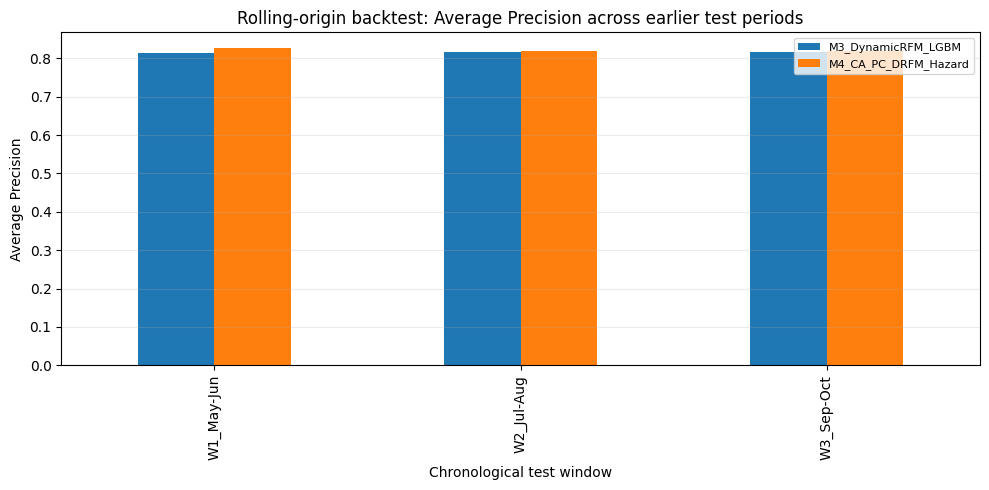

In [112]:
# Three expanding-window backtests. The primary paper-aligned split remains untouched.
rolling_windows = [
    {"window": "W1_May-Jun", "train_end": "2011-03-01", "validation_end": "2011-05-01", "test_end": "2011-07-01"},
    {"window": "W2_Jul-Aug", "train_end": "2011-05-01", "validation_end": "2011-07-01", "test_end": "2011-09-01"},
    {"window": "W3_Sep-Oct", "train_end": "2011-07-01", "validation_end": "2011-09-01", "test_end": "2011-10-16"},
]
rolling_records = []

for spec in rolling_windows:
    train_end = pd.Timestamp(spec["train_end"])
    validation_end = pd.Timestamp(spec["validation_end"])
    test_end = pd.Timestamp(spec["test_end"])
    window_rows = {
        "train": snapshots.loc[pd.to_datetime(snapshots["snapshot_date"]) < train_end].copy(),
        "validation": snapshots.loc[
            (pd.to_datetime(snapshots["snapshot_date"]) >= train_end)
            & (pd.to_datetime(snapshots["snapshot_date"]) < validation_end)
        ].copy(),
        "test": snapshots.loc[
            (pd.to_datetime(snapshots["snapshot_date"]) >= validation_end)
            & (pd.to_datetime(snapshots["snapshot_date"]) < test_end)
        ].copy(),
    }
    window_ends = {"train": train_end, "validation": validation_end, "test": test_end}
    window_obs = {
        part: attach_time_to_event(window_rows[part], invoices, window_ends[part], cfg.horizon_days)
        for part in ["train", "validation", "test"]
    }
    window_labels = {
        part: make_horizon_label(window_obs[part], cfg.classification_horizon_days, require_full_followup=True)
        for part in ["train", "validation", "test"]
    }
    print(
        spec["window"],
        {part: {"states": len(window_rows[part]), "complete_30d": len(window_labels[part]),
                "positive_rate": float(window_labels[part]["target"].mean()) if len(window_labels[part]) else np.nan}
         for part in ["train", "validation", "test"]}
    )
    if any(window_labels[p].empty or window_labels[p]["target"].nunique() < 2 for p in ["train", "validation", "test"]):
        print(f"Bỏ qua {spec['window']}: không đủ hai lớp trong một partition sau khi yêu cầu đủ follow-up.")
        continue

    for seed in SEEDS:
        # M3: strong binary classifier, trained only on fully observed 30-day Train labels.
        m3 = make_binary_models(seed, cfg.n_estimators)["M3_DynamicRFM_LGBM"]
        m3.fit(_clean_X(window_labels["train"], dynamic_features), window_labels["train"]["target"].astype(int))
        m3_val = m3.predict_proba(_clean_X(window_labels["validation"], dynamic_features))[:, 1]
        m3_threshold = choose_threshold(window_labels["validation"]["target"].to_numpy(dtype=int), m3_val)
        m3_test = m3.predict_proba(_clean_X(window_labels["test"], dynamic_features))[:, 1]
        m3_metrics = binary_metrics(window_labels["test"]["target"].to_numpy(dtype=int), m3_test, m3_threshold)
        m3_metrics.update({
            "window": spec["window"], "model": "M3_DynamicRFM_LGBM", "seed": seed,
            "train_end": train_end, "validation_end": validation_end, "test_end": test_end,
            "n_train_complete_30d": len(window_labels["train"]),
            "n_validation_complete_30d": len(window_labels["validation"]),
            "n_test_complete_30d": len(window_labels["test"]),
            "n_test_customers": int(window_labels["test"]["CustomerID"].nunique()),
        })
        rolling_records.append(m3_metrics)

        # M4: discrete-time hazard; censored partial intervals in Train contribute correctly.
        pp = build_person_period(window_obs["train"], dynamic_features, cfg)
        hazard_cols = dynamic_features + ["period_idx", "period_lower", "period_upper"]
        m4 = make_hazard_model(seed, cfg.n_estimators)
        m4.fit(_clean_X(pp, hazard_cols), pp["hazard_event"].astype(int))
        m4_val = predict_hazard_risk(
            m4, window_labels["validation"], dynamic_features, cfg.interval_edges, cfg.classification_horizon_days
        )
        m4_threshold = choose_threshold(window_labels["validation"]["target"].to_numpy(dtype=int), m4_val)
        m4_test = predict_hazard_risk(
            m4, window_labels["test"], dynamic_features, cfg.interval_edges, cfg.classification_horizon_days
        )
        m4_metrics = binary_metrics(window_labels["test"]["target"].to_numpy(dtype=int), m4_test, m4_threshold)
        m4_metrics.update({
            "window": spec["window"], "model": "M4_CA_PC_DRFM_Hazard", "seed": seed,
            "train_end": train_end, "validation_end": validation_end, "test_end": test_end,
            "n_train_survival_states": len(window_obs["train"]),
            "n_train_person_period_rows": len(pp),
            "n_validation_complete_30d": len(window_labels["validation"]),
            "n_test_complete_30d": len(window_labels["test"]),
            "n_test_customers": int(window_labels["test"]["CustomerID"].nunique()),
        })
        rolling_records.append(m4_metrics)

rolling_backtest = pd.DataFrame(rolling_records)
rolling_backtest.to_csv(RESULTS_DIR / "rolling_origin_backtest_by_seed.csv", index=False)
if not rolling_backtest.empty:
    rolling_summary = rolling_backtest.groupby(["window", "model"])[
        ["average_precision", "roc_auc", "f1", "brier_30d", "n_test", "n_test_customers"]
    ].agg(["mean", "std"])
    display(rolling_summary)
    rolling_summary.to_csv(RESULTS_DIR / "rolling_origin_backtest_summary.csv")

    # Per-window paired deltas show consistency; do not pool these overlapping customer histories as independent samples.
    delta_rows = []
    for window, part in rolling_backtest.groupby("window"):
        wide = part.pivot(index="seed", columns="model", values="average_precision")
        if {"M3_DynamicRFM_LGBM", "M4_CA_PC_DRFM_Hazard"}.issubset(wide.columns):
            delta = wide["M4_CA_PC_DRFM_Hazard"] - wide["M3_DynamicRFM_LGBM"]
            delta_rows.append({
                "window": window, "mean_delta_AP_M4_minus_M3": float(delta.mean()),
                "sd_delta_AP_across_seeds": float(delta.std(ddof=1)) if len(delta) > 1 else np.nan,
                "seeds_M4_wins": int((delta > 0).sum()), "n_seeds": int(len(delta)),
            })
    rolling_delta = pd.DataFrame(delta_rows)
    rolling_delta.to_csv(RESULTS_DIR / "rolling_origin_delta_ap.csv", index=False)
    display(rolling_delta)

    fig, ax = plt.subplots(figsize=(10, 5))
    pivot_ap = rolling_backtest.pivot_table(index="window", columns="model", values="average_precision", aggfunc="mean")
    pivot_ap.plot(kind="bar", ax=ax)
    ax.set_title("Rolling-origin backtest: Average Precision across earlier test periods")
    ax.set_ylabel("Average Precision")
    ax.set_xlabel("Chronological test window")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "rolling_origin_backtest_ap.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Không có rolling-origin result; kiểm tra số lớp và follow-up của các cửa sổ.")


## 12. Biểu đồ đánh giá

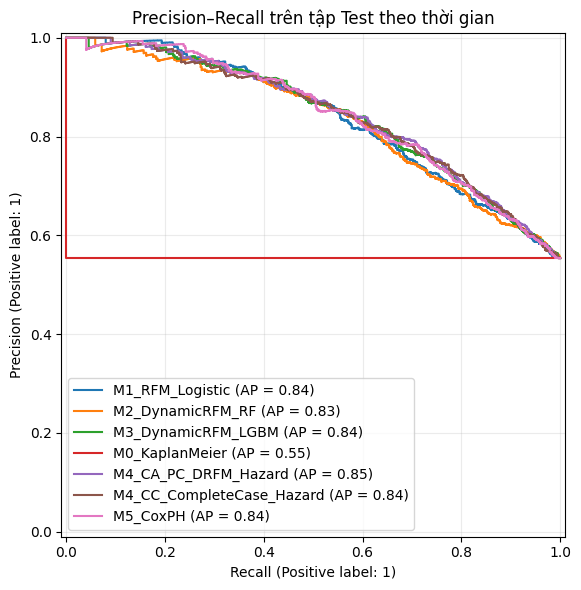

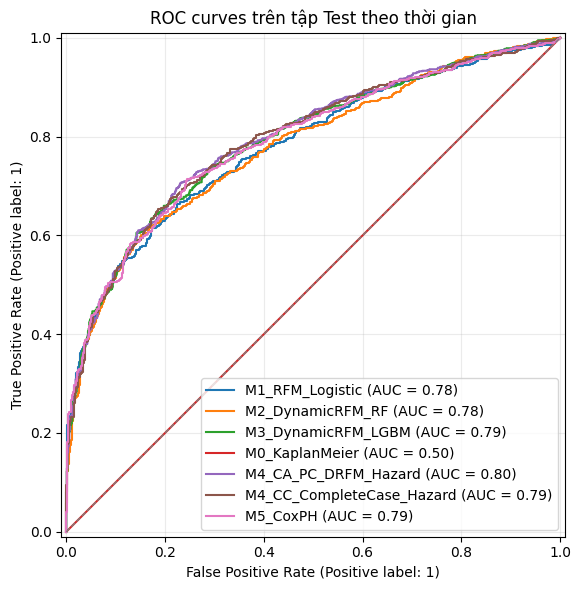

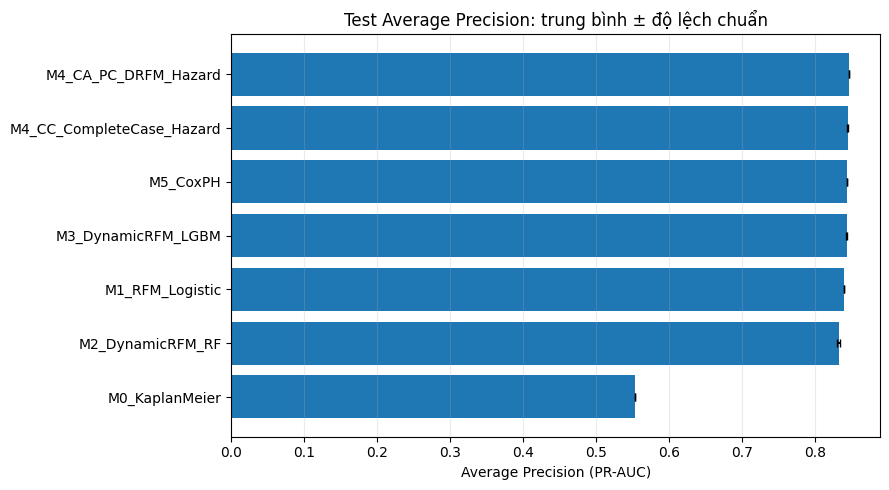

In [113]:
# Precision–Recall curves
fig, ax = plt.subplots(figsize=(8, 6))
for model_name, frame in all_predictions_seed42.items():
    y = frame["target"].to_numpy()
    p = frame["probability"].to_numpy()
    if len(np.unique(y)) == 2:
        PrecisionRecallDisplay.from_predictions(y, p, name=model_name, ax=ax)
ax.set_title("Precision–Recall trên tập Test theo thời gian")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_precision_recall.png", dpi=160)
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(8, 6))
for model_name, frame in all_predictions_seed42.items():
    y = frame["target"].to_numpy()
    p = frame["probability"].to_numpy()
    if len(np.unique(y)) == 2:
        RocCurveDisplay.from_predictions(y, p, name=model_name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax.set_title("ROC curves trên tập Test theo thời gian")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_roc_curves.png", dpi=160)
plt.show()

# So sánh Average Precision trung bình (nếu có nhiều seed)
plot_data = summary.dropna(subset=["average_precision_mean"]).sort_values("average_precision_mean")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data["model"], plot_data["average_precision_mean"],
        xerr=plot_data["average_precision_std"].fillna(0), capsize=3)
ax.set_xlabel("Average Precision (PR-AUC)")
ax.set_title("Test Average Precision: trung bình ± độ lệch chuẩn")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_metric_summary.png", dpi=160)
plt.show()

## 12.1. Biểu đồ so sánh mở rộng

Các biểu đồ dưới đây sử dụng kết quả Test. Dashboard trình bày trung bình ± độ lệch chuẩn qua 5 seed; đường PR/ROC và ma trận nhầm lẫn minh họa seed 42. Test không được dùng để chọn ngưỡng hoặc điều chỉnh mô hình.

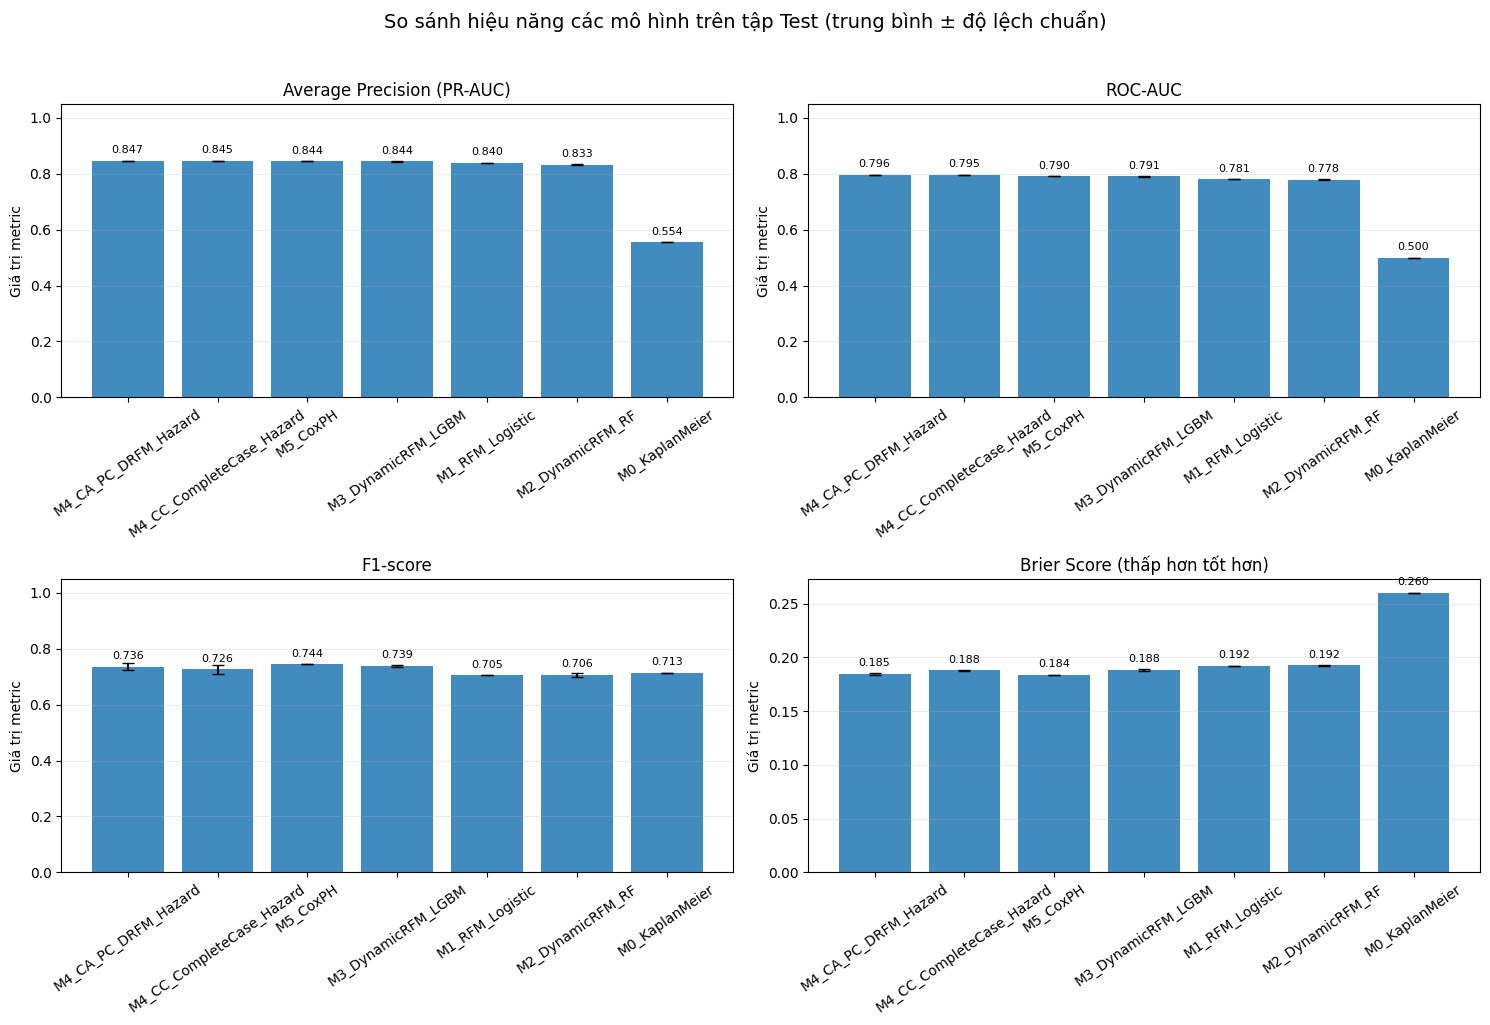

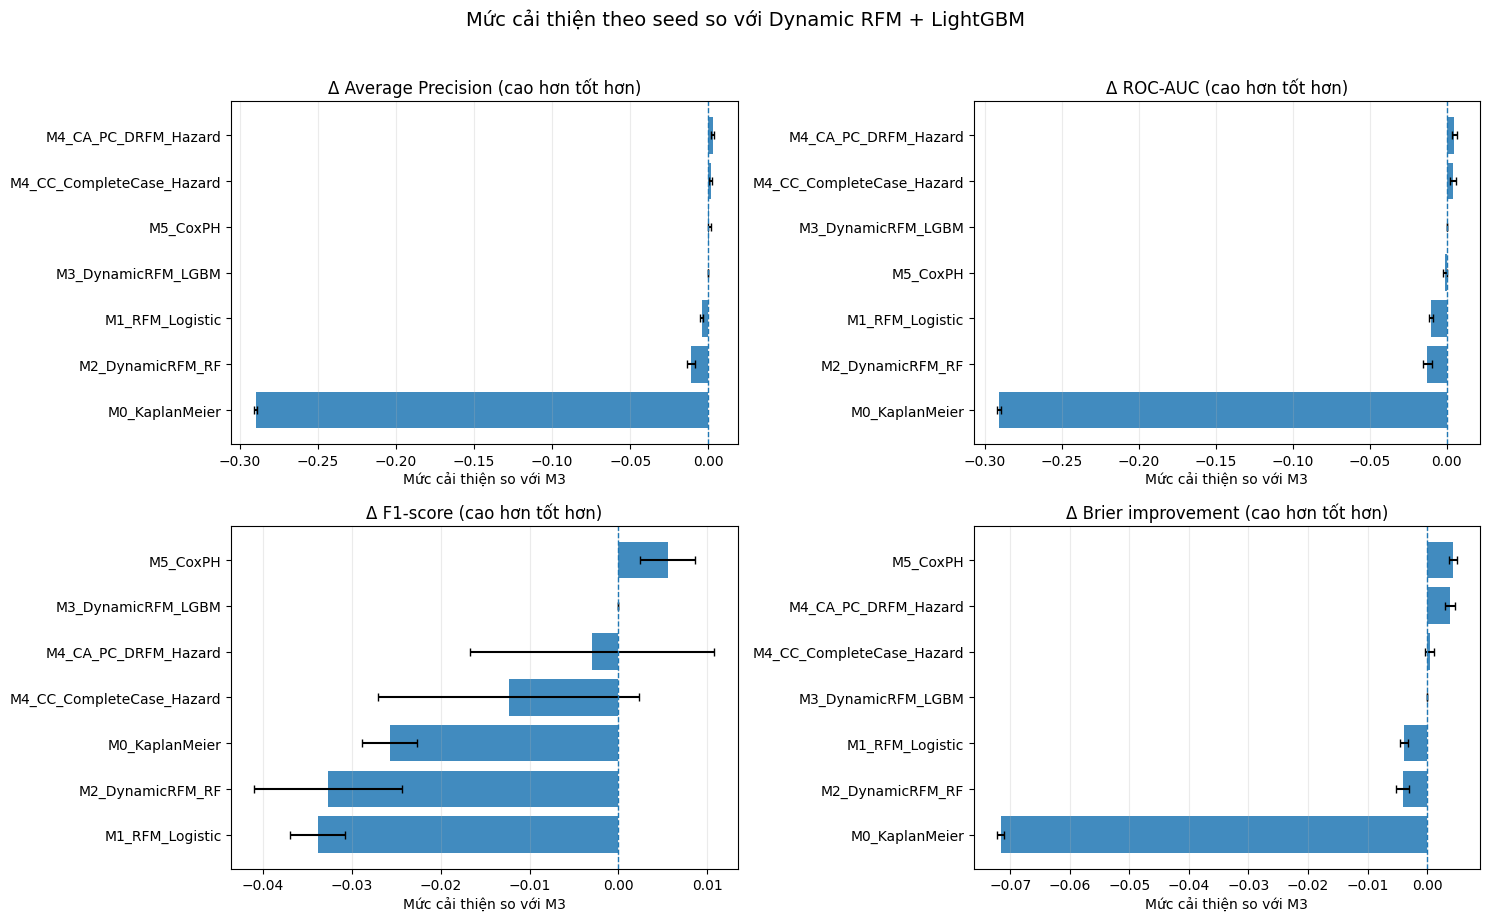

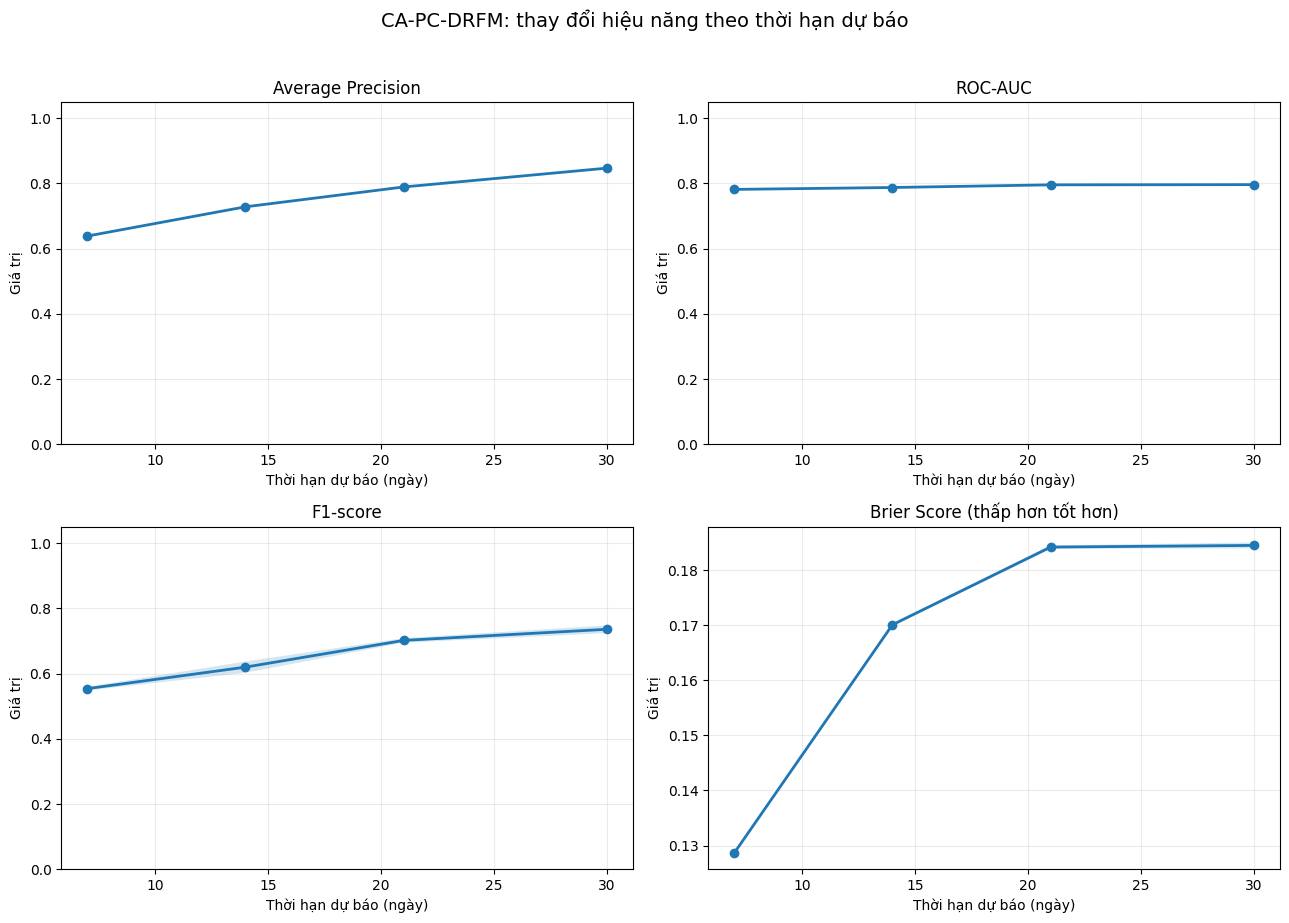

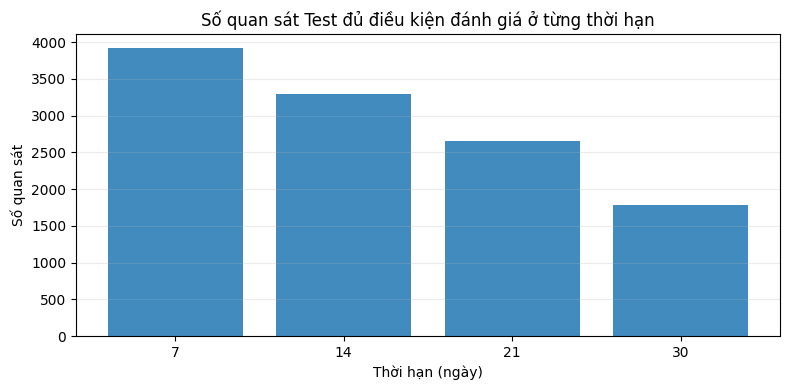

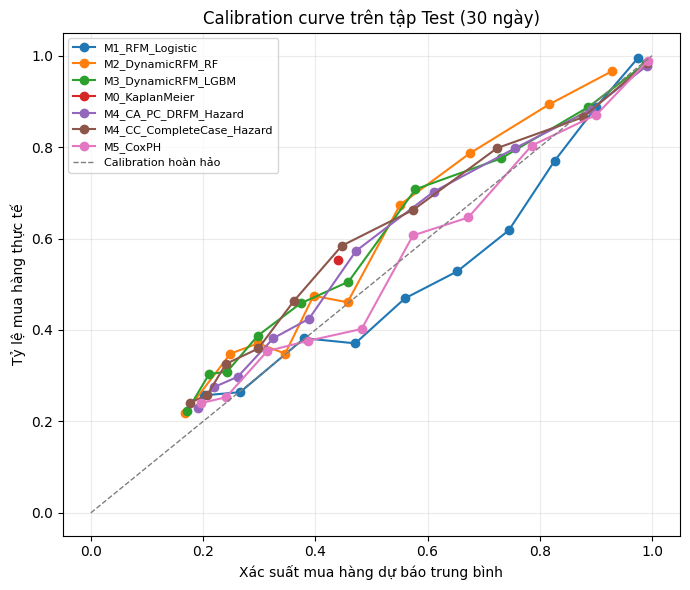

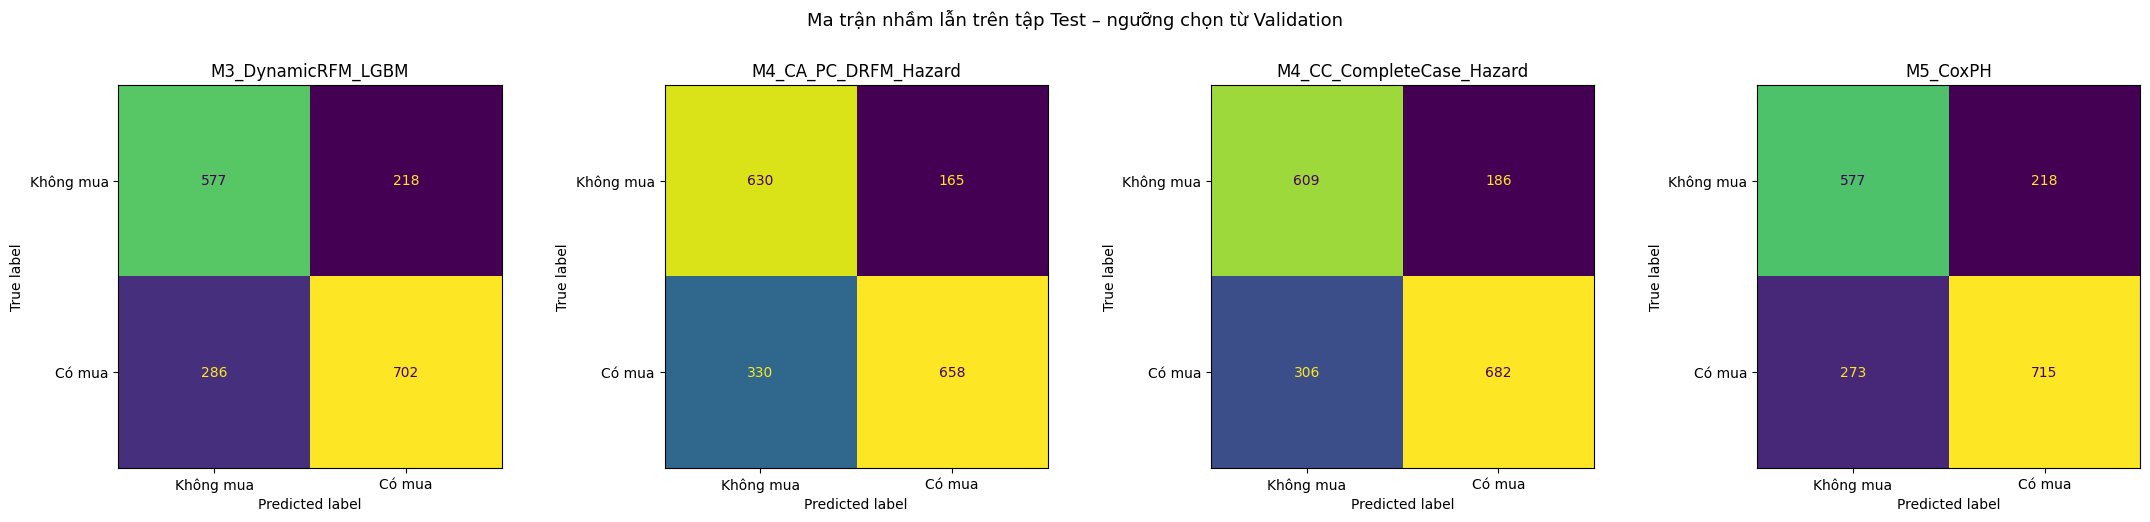

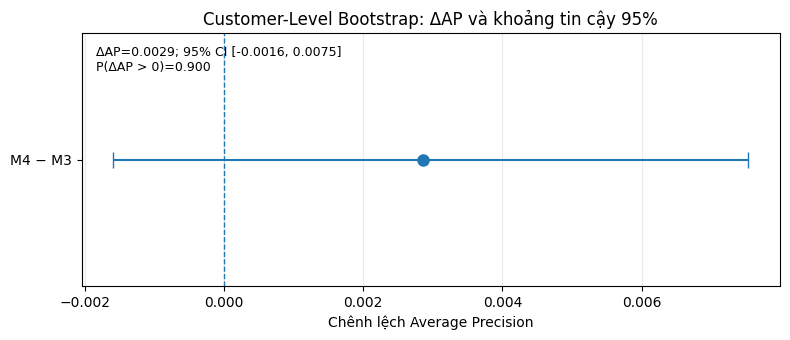

Đã lưu các biểu đồ so sánh mở rộng vào: /content/ca_pc_drfm/results


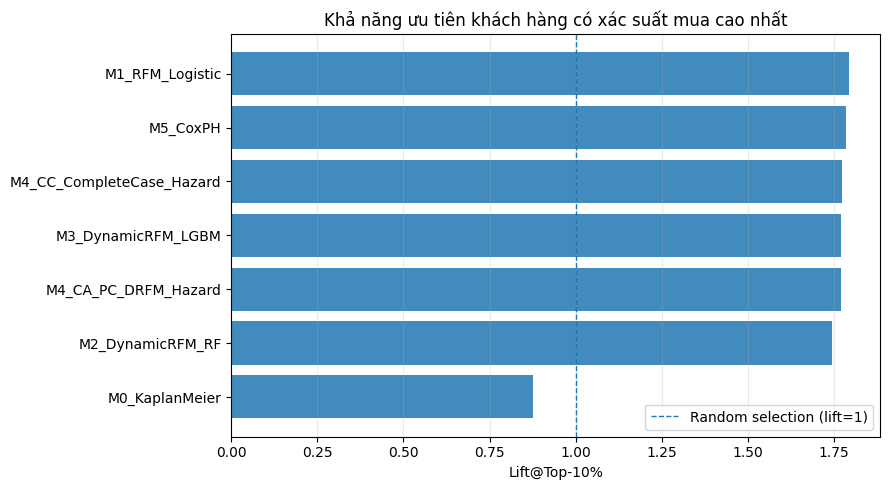

In [114]:
# 12.1.1. Dashboard so sánh nhiều metric trên cùng tập Test
from pathlib import Path
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

comparison_specs = [
    ("average_precision", "Average Precision (PR-AUC)", True),
    ("roc_auc", "ROC-AUC", True),
    ("f1", "F1-score", True),
    ("brier_30d", "Brier Score (thấp hơn tốt hơn)", False),
]

available_specs = [
    (metric, title, higher_is_better)
    for metric, title, higher_is_better in comparison_specs
    if f"{metric}_mean" in summary.columns
]

if available_specs:
    model_order = summary.sort_values(
        "average_precision_mean", ascending=False
    )["model"].tolist() if "average_precision_mean" in summary.columns else summary["model"].tolist()
    plot_summary = summary.set_index("model").reindex(model_order).reset_index()

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    for ax, (metric, title, higher_is_better) in zip(axes.flat, available_specs):
        means = plot_summary[f"{metric}_mean"].astype(float)
        std_col = f"{metric}_std"
        errors = plot_summary[std_col].fillna(0).astype(float) if std_col in plot_summary else np.zeros(len(means))
        bars = ax.bar(
            plot_summary["model"], means,
            yerr=errors, capsize=4, alpha=0.85
        )
        ax.set_title(title)
        ax.set_ylabel("Giá trị metric")
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=0.25)
        ax.set_ylim(bottom=0)
        if metric != "brier_30d":
            ax.set_ylim(0, 1.05)
        for bar, value in zip(bars, means):
            if pd.notna(value):
                ax.annotate(
                    f"{value:.3f}",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8
                )
    for ax in axes.flat[len(available_specs):]:
        ax.set_visible(False)
    fig.suptitle("So sánh hiệu năng các mô hình trên tập Test (trung bình ± độ lệch chuẩn)", y=1.02, fontsize=14)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "comparison_metric_dashboard.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Chưa có metric phù hợp để vẽ dashboard.")


# 12.1.2. Mức cải thiện của từng mô hình so với Dynamic RFM + LightGBM (M3)
# Với Brier Score, dấu được đảo để giá trị dương luôn có nghĩa là tốt hơn baseline.
baseline_name = "M3_DynamicRFM_LGBM"
delta_specs = [
    ("average_precision", "Δ Average Precision (cao hơn tốt hơn)", 1),
    ("roc_auc", "Δ ROC-AUC (cao hơn tốt hơn)", 1),
    ("f1", "Δ F1-score (cao hơn tốt hơn)", 1),
    ("brier_30d", "Δ Brier improvement (cao hơn tốt hơn)", -1),
]

delta_records = []
if baseline_name in set(binary_frame["model"]):
    for metric, title, direction in delta_specs:
        pivot = binary_frame.pivot_table(index="seed", columns="model", values=metric, aggfunc="mean")
        if baseline_name not in pivot.columns:
            continue
        for model_name in pivot.columns:
            if model_name == baseline_name:
                paired = pivot[[baseline_name]].dropna()
                if paired.empty:
                    continue
                deltas = pd.Series(np.zeros(len(paired)), index=paired.index)
            else:
                paired = pivot[[baseline_name, model_name]].dropna()
                if paired.empty:
                    continue
                deltas = direction * (paired[model_name] - paired[baseline_name])
            delta_records.append({
                "metric": metric,
                "title": title,
                "model": model_name,
                "mean_delta": float(deltas.mean()),
                "std_delta": float(deltas.std(ddof=1)) if len(deltas) > 1 else 0.0,
                "n_seeds": int(len(deltas)),
            })

delta_frame = pd.DataFrame(delta_records)
if not delta_frame.empty:
    delta_frame.to_csv(RESULTS_DIR / "metric_delta_vs_m3.csv", index=False)
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, (metric, title, _) in zip(axes.flat, delta_specs):
        subset = delta_frame[delta_frame["metric"] == metric].copy()
        if subset.empty:
            ax.set_visible(False)
            continue
        subset = subset.sort_values("mean_delta")
        ax.barh(subset["model"], subset["mean_delta"], xerr=subset["std_delta"], capsize=3, alpha=0.85)
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set_title(title)
        ax.set_xlabel("Mức cải thiện so với M3")
        ax.grid(axis="x", alpha=0.25)
    fig.suptitle("Mức cải thiện theo seed so với Dynamic RFM + LightGBM", y=1.02, fontsize=14)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "comparison_delta_vs_m3.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Không tạo được biểu đồ delta: thiếu M3 hoặc dữ liệu metric theo seed.")


# 12.1.3. Hiệu năng CA-PC-DRFM theo các mốc dự báo 7–90 ngày
if "horizon_frame" in globals() and not horizon_frame.empty:
    horizon_summary = horizon_frame.groupby("horizon_days").agg(
        average_precision_mean=("average_precision", "mean"),
        average_precision_std=("average_precision", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        f1_mean=("f1", "mean"),
        f1_std=("f1", "std"),
        brier_mean=("brier_score", "mean"),
        brier_std=("brier_score", "std"),
        n_test_mean=("n_test", "mean"),
        positive_rate_mean=("positive_rate", "mean"),
    ).reset_index().sort_values("horizon_days")
    horizon_summary.to_csv(RESULTS_DIR / "horizon_metric_summary.csv", index=False)

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    horizon_plot_specs = [
        ("average_precision", "average_precision_mean", "average_precision_std", "Average Precision"),
        ("roc_auc", "roc_auc_mean", "roc_auc_std", "ROC-AUC"),
        ("f1", "f1_mean", "f1_std", "F1-score"),
        ("brier", "brier_mean", "brier_std", "Brier Score (thấp hơn tốt hơn)"),
    ]
    for ax, (_, mean_col, std_col, title) in zip(axes.flat, horizon_plot_specs):
        x = horizon_summary["horizon_days"].to_numpy()
        y = horizon_summary[mean_col].to_numpy(dtype=float)
        sd = horizon_summary[std_col].fillna(0).to_numpy(dtype=float)
        ax.plot(x, y, marker="o", linewidth=2)
        ax.fill_between(x, np.maximum(0, y - sd), y + sd, alpha=0.18)
        ax.set_title(title)
        ax.set_xlabel("Thời hạn dự báo (ngày)")
        ax.set_ylabel("Giá trị")
        ax.grid(alpha=0.25)
        if title != "Brier Score (thấp hơn tốt hơn)":
            ax.set_ylim(0, 1.05)
    fig.suptitle("CA-PC-DRFM: thay đổi hiệu năng theo thời hạn dự báo", y=1.02, fontsize=14)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "comparison_horizon_metrics.png", dpi=180, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(horizon_summary["horizon_days"].astype(str), horizon_summary["n_test_mean"], alpha=0.85)
    ax.set_title("Số quan sát Test đủ điều kiện đánh giá ở từng thời hạn")
    ax.set_xlabel("Thời hạn (ngày)")
    ax.set_ylabel("Số quan sát")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "comparison_horizon_sample_counts.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Không có horizon_frame; bỏ qua biểu đồ theo thời hạn.")


# 12.1.4. Biểu đồ Calibration: xác suất dự báo có phù hợp với tỷ lệ mua thực tế?
calibration_records = []
fig, ax = plt.subplots(figsize=(7, 6))
for model_name, frame in all_predictions_seed42.items():
    y = frame["target"].to_numpy(dtype=int)
    probability = frame["probability"].to_numpy(dtype=float)
    if len(np.unique(y)) < 2 or len(probability) < 10:
        continue
    observed_fraction, mean_predicted = calibration_curve(
        y, probability, n_bins=min(10, max(3, len(y) // 20)), strategy="quantile"
    )
    ax.plot(mean_predicted, observed_fraction, marker="o", linewidth=1.5, label=model_name)
    calibration_records.append({"model": model_name, "n_test": len(y), "n_bins": len(mean_predicted)})
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Calibration hoàn hảo")
ax.set_title("Calibration curve trên tập Test (30 ngày)")
ax.set_xlabel("Xác suất mua hàng dự báo trung bình")
ax.set_ylabel("Tỷ lệ mua hàng thực tế")
ax.grid(alpha=0.25)
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "comparison_calibration.png", dpi=180, bbox_inches="tight")
plt.show()
pd.DataFrame(calibration_records).to_csv(RESULTS_DIR / "calibration_plot_info.csv", index=False)


# 12.1.5. Ma trận nhầm lẫn của M3 và M4 trên cùng tập Test
selected_for_cm = [name for name in ["M3_DynamicRFM_LGBM", "M4_CA_PC_DRFM_Hazard", "M4_CC_CompleteCase_Hazard", "M5_CoxPH"] if name in all_predictions_seed42]
if selected_for_cm:
    fig, axes = plt.subplots(1, len(selected_for_cm), figsize=(5.5 * len(selected_for_cm), 5))
    if len(selected_for_cm) == 1:
        axes = [axes]
    for ax, model_name in zip(axes, selected_for_cm):
        frame = all_predictions_seed42[model_name]
        matrix = confusion_matrix(frame["target"], frame["prediction"], labels=[0, 1])
        disp = ConfusionMatrixDisplay(matrix, display_labels=["Không mua", "Có mua"])
        disp.plot(ax=ax, values_format="d", colorbar=False)
        ax.set_title(model_name)
    fig.suptitle("Ma trận nhầm lẫn trên tập Test – ngưỡng chọn từ Validation", y=1.02, fontsize=13)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "comparison_confusion_matrices.png", dpi=180, bbox_inches="tight")
    plt.show()


# 12.1.6. Khoảng tin cậy Bootstrap cho chênh lệch Average Precision (M4 − M3)
if "bootstrap_result" in globals() and bootstrap_result:
    delta = float(bootstrap_result["delta_average_precision_mean"])
    lower = float(bootstrap_result["ci95_lower"])
    upper = float(bootstrap_result["ci95_upper"])
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.errorbar(
        delta, 0,
        xerr=[[max(0.0, delta - lower)], [max(0.0, upper - delta)]],
        fmt="o", capsize=6, markersize=8
    )
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_yticks([0], ["M4 − M3"])
    ax.set_xlabel("Chênh lệch Average Precision")
    ax.set_title("Customer-Level Bootstrap: ΔAP và khoảng tin cậy 95%")
    ax.grid(axis="x", alpha=0.25)
    ax.text(
        0.02, 0.95,
        f"ΔAP={delta:.4f}; 95% CI [{lower:.4f}, {upper:.4f}]\nP(ΔAP > 0)={bootstrap_result['probability_delta_positive']:.3f}",
        transform=ax.transAxes, va="top", fontsize=9
    )
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "comparison_bootstrap_delta_ap.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Không có bootstrap_result; hãy chạy cell kiểm định trước để vẽ CI Bootstrap.")

print("Đã lưu các biểu đồ so sánh mở rộng vào:", RESULTS_DIR)


# 12.1.7. So sánh năng lực ưu tiên CRM: Lift@Top-10%
if "top_fraction_summary" in globals() and not top_fraction_summary.empty:
    _lift = top_fraction_summary["lift_at_top_fraction"]["mean"].sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(_lift.index, _lift.values, alpha=0.85)
    ax.axvline(1.0, linestyle="--", linewidth=1, label="Random selection (lift=1)")
    ax.set_xlabel("Lift@Top-10%")
    ax.set_title("Khả năng ưu tiên khách hàng có xác suất mua cao nhất")
    ax.grid(axis="x", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "comparison_top_decile_lift.png", dpi=180, bbox_inches="tight")
    plt.show()


## 13. Feature importance và ví dụ dự báo sống còn

In [115]:
if feature_importance_records:
    importance_frame = pd.DataFrame(feature_importance_records)
    importance_frame.to_csv(RESULTS_DIR / "feature_importance_by_seed.csv", index=False)
    importance_mean = importance_frame.groupby(["model", "feature"], as_index=False)["importance"].mean()
    importance_mean.to_csv(RESULTS_DIR / "feature_importance_mean.csv", index=False)
    display(importance_mean.sort_values("importance", ascending=False).head(25))

if all_survival_predictions_seed42 is not None:
    all_survival_predictions_seed42.to_csv(RESULTS_DIR / "survival_predictions_seed42.csv", index=False)
    display(all_survival_predictions_seed42.head(10))

    # Minh họa các đường xác suất mua tích lũy ở các mốc thời gian.
    example = all_survival_predictions_seed42.head(50)
    mean_risk = example[["risk_7d", "risk_30d", "risk_60d", "risk_90d"]].mean()
    display(mean_risk.rename("mean_predicted_purchase_probability").to_frame())

,model,feature,importance
437,M4_CA_PC_DRFM_Hazard,period_idx,431.2
600,M4_CC_CompleteCase_Hazard,period_idx,265.0
481,M4_CA_PC_DRFM_Hazard,snapshot_month_cos,183.0
644,M4_CC_CompleteCase_Hazard,snapshot_month_cos,142.4
318,M3_DynamicRFM_LGBM,snapshot_month_cos,128.4
161,M3_DynamicRFM_LGBM,average_order_value,100.0
447,M4_CA_PC_DRFM_Hazard,recency_days,97.2
284,M3_DynamicRFM_LGBM,recency_days,95.2
367,M4_CA_PC_DRFM_Hazard,ipi_std_days,92.2
484,M4_CC_CompleteCase_Hazard,average_order_value,89.2


,CustomerID,current_invoice_no,state_timestamp,snapshot_date,duration_days,event_observed,followup_days,risk_7d,risk_30d,risk_45d,risk_60d,risk_90d,risk_60d_90d_note
0,12901,571259,2011-10-16 10:19:00,2011-10-16,0.021528,True,54.570139,0.294165,0.882913,0.967080,0.990685,0.997682,model extrapolation only where test follow-up ...
1,12901,571261,2011-10-16 10:50:00,2011-10-16,11.066667,True,54.548611,0.322912,0.892234,0.968364,0.990713,0.997689,model extrapolation only where test follow-up ...
2,12940,571270,2011-10-16 12:09:00,2011-10-16,54.493750,False,54.493750,0.098255,0.369201,0.578215,0.717973,0.873476,model extrapolation only where test follow-up ...
3,13034,571273,2011-10-16 12:21:00,2011-10-16,54.485417,False,54.485417,0.077363,0.243940,0.388449,0.505337,0.686662,model extrapolation only where test follow-up ...
4,13610,571291,2011-10-16 15:44:00,2011-10-16,41.995833,True,54.344444,0.075849,0.319708,0.601506,0.766574,0.893928,model extrapolation only where test follow-up ...
5,13760,571296,2011-10-16 16:13:00,2011-10-16,54.324306,False,54.324306,0.057738,0.182813,0.291787,0.386229,0.526245,model extrapolation only where test follow-up ...
6,13878,571272,2011-10-16 12:19:00,2011-10-16,54.486806,False,54.486806,0.085008,0.254413,0.379142,0.483005,0.635304,model extrapolation only where test follow-up ...
7,13956,571293,2011-10-16 15:56:00,2011-10-16,48.891667,True,54.336111,0.115348,0.359250,0.594639,0.744356,0.874169,model extrapolation only where test follow-up ...
8,14088,571281,2011-10-16 13:23:00,2011-10-16,17.060417,True,54.442361,0.426781,0.859230,0.948505,0.981163,0.993447,model extrapolation only where test follow-up ...
9,14547,571286,2011-10-16 14:35:00,2011-10-16,21.002778,True,54.392361,0.070849,0.218986,0.328685,0.422976,0.563269,model extrapolation only where test follow-up ...


,mean_predicted_purchase_probability
risk_7d,0.157818
risk_30d,0.443597
risk_60d,0.697843
risk_90d,0.808490


## 14. Lưu thông tin chia dữ liệu và toàn bộ kết quả

In [116]:
split_info = {
    "dataset": "UCI Online Retail I",
    "notebook_version": "CA-PC-DRFM v4",
    "exact_duplicate_policy_primary": "preserve" if not cfg.deduplicate_exact_lines else "drop",
    "model_roster": ["M0_KaplanMeier", "M1_RFM_Logistic", "M2_DynamicRFM_RF", "M3_DynamicRFM_LGBM", "M4_CA_PC_DRFM_Hazard", "M4_CC_CompleteCase_Hazard", "M5_CoxPH"],
    "reference_paper": "LLM-Augmented Customer Representation Learning for Next-Purchase Prediction in Online Retail",
    "sampling_unit": "one customer-invoice state (CustomerID x InvoiceNo)",
    "primary_design": "chronological split + partition-boundary right censoring + discrete-time hazard",
    "paper_benchmark_design": "separate legacy observed-next-invoice-within-30d label for protocol comparison only",
    "paper_calendar_split": {
        "train": "before 2011-09-01",
        "validation": "2011-09-01 through 2011-10-15",
        "test": "2011-10-16 through observed end 2011-12-09",
    },
    "paper_published_state_counts": {"train": 11439, "validation": 2656, "test": 4467},
    "paper_published_positive_counts": {"train": 5114, "validation": 1198, "test": 2044},
    "local_partition_state_counts": {name: int(len(frame)) for name, frame in split_rows.items()},
    "local_partition_customer_counts": {name: int(frame["CustomerID"].nunique()) for name, frame in split_rows.items()},
    "local_partition_share": {name: float(len(frame) / len(snapshots)) for name, frame in split_rows.items()},
    "train_start": str(pd.Timestamp(split_rows["train"]["snapshot_date"].min()).date()),
    "train_last_state_date": str(pd.Timestamp(split_rows["train"]["snapshot_date"].max()).date()),
    "train_followup_censored_at": str(pd.Timestamp(split["train_end"]).date()),
    "validation_start": str(pd.Timestamp(split_rows["validation"]["snapshot_date"].min()).date()),
    "validation_last_state_date": str(pd.Timestamp(split_rows["validation"]["snapshot_date"].max()).date()),
    "validation_followup_censored_at": str(pd.Timestamp(split["validation_end"]).date()),
    "test_start": str(pd.Timestamp(split_rows["test"]["snapshot_date"].min()).date()),
    "test_last_state_date": str(pd.Timestamp(split_rows["test"]["snapshot_date"].max()).date()),
    "test_followup_end_exclusive": str(pd.Timestamp(split["test_end"]).date()),
    "n_test_complete_30d": int(len(binary_sets["test"])),
    "test_complete_30d_positive_rate": float(binary_sets["test"]["target"].mean()),
    "n_test_customer_clusters": int(binary_sets["test"]["CustomerID"].nunique()),
    "snapshot_frequency_days": "invoice-state (calendar snapshots not used for modeling)",
    "survival_horizon_days": cfg.horizon_days,
    "classification_horizon_days": cfg.classification_horizon_days,
    "cycle_shrinkage_strength": cfg.cycle_shrinkage_strength,
    "cycle_prior_days": cfg.adaptive_window_default_days,
    "seeds": SEEDS,
    "n_estimators": cfg.n_estimators,
    "n_bootstrap_repeats": cfg.bootstrap_repeats,
    "cox_features": select_cox_features(observations["train"]),
    "cox_penalizer": 0.05,
    "cox_features": select_cox_features(observations["train"]),
    "cox_penalizer": 0.05,
    "lightgbm_required": True,
    "cox_ph_implemented_with": "penalized Cox partial likelihood, Breslow tie handling, SciPy L-BFGS-B",
    "note": "The article's published sample shares refer to invoice states, not weekly snapshots. Compare local counts and label positives in the audit files; do not force counts.",
}
(RESULTS_DIR / "split_info.json").write_text(
    json.dumps(split_info, indent=2, ensure_ascii=False), encoding="utf-8"
)

for model_name, prediction in all_predictions_seed42.items():
    prediction.to_csv(RESULTS_DIR / f"test_predictions_{model_name}_seed42.csv", index=False)
if all_survival_predictions_seed42 is not None:
    all_survival_predictions_seed42.to_csv(RESULTS_DIR / "survival_predictions_seed42.csv", index=False)

if "cox_coefficients_frame" in globals():
    cox_coefficients_frame.to_csv(RESULTS_DIR / "cox_ph_coefficients_by_seed.csv", index=False)
if "top_fraction_frame" in globals():
    top_fraction_frame.to_csv(RESULTS_DIR / "top_decile_metrics_by_seed.csv", index=False)
print("Đã lưu kết quả tại:", RESULTS_DIR)
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f" - {path.name} ({path.stat().st_size:,} bytes)")

Đã lưu kết quả tại: /content/ca_pc_drfm/results
 - .gitkeep (0 bytes)
 - calibration_plot_info.csv (198 bytes)
 - censoring_and_label_audit.csv (503 bytes)
 - chronological_split_summary.csv (467 bytes)
 - cleaned_customer_invoices.csv (1,198,652 bytes)
 - comparison_bootstrap_delta_ap.png (47,674 bytes)
 - comparison_calibration.png (172,059 bytes)
 - comparison_confusion_matrices.png (93,443 bytes)
 - comparison_delta_vs_m3.png (210,168 bytes)
 - comparison_horizon_metrics.png (137,525 bytes)
 - comparison_horizon_sample_counts.png (45,272 bytes)
 - comparison_metric_dashboard.png (271,819 bytes)
 - comparison_top_decile_lift.png (73,526 bytes)
 - cox_ph_coefficients_by_seed.csv (5,313 bytes)
 - customer_balanced_metrics_by_seed.csv (6,333 bytes)
 - customer_bootstrap_comparison.csv (596 bytes)
 - customer_cluster_bootstrap_metrics.csv (2,503 bytes)
 - customer_dynamic_rfm_snapshots.csv.gz (8,222,390 bytes)
 - customer_invoice_states.csv.gz (8,621,711 bytes)
 - deduplication_sensitiv

## Hướng dẫn diễn giải và nguyên tắc kết luận — v4

1. **Primary survival comparison:** M4 (CA-PC-DRFM discrete-time hazard) so với M3 (Dynamic RFM + LightGBM classification), M4-CC (complete-case hazard) và M5 (penalized Cox PH) trên cùng cohort Test có đủ 30 ngày follow-up.
2. **Censor-aware contribution:** M4 vs M4-CC là ablation về việc giữ lại các khoảng follow-up bị kiểm duyệt một phần trong likelihood. Nếu CI chứa 0, không kết luận có cải thiện thống kê.
3. **Survival baseline:** M5 là Cox Proportional Hazards với L2 penalty và Breslow ties, fit trên các purchase-gap spells. Khách hàng đóng góp nhiều spells; do đó mọi suy luận chênh lệch phải resample theo CustomerID, không xem các hàng invoice-state là độc lập.
4. **Paper-protocol benchmark:** `paper_protocol_metrics_by_seed.csv` đánh giá thêm M1/M3/M4/M4-CC theo nhãn quan sát của bài báo. Bảng công bố tách `f1_at_published_threshold` và `best_f1_test_oracle`; không được gộp hai giá trị thành một cột F1.
5. **Threshold policy:** F1 vận hành (`f1`) dùng threshold chọn trên Validation; `best_f1_test_oracle` là chỉ số nhìn lại trên Test để đối chiếu, tuyệt đối không dùng chọn mô hình hoặc triển khai.
6. **Top-decile CRM metrics:** Precision/Recall/Lift@Top-10% xếp hạng theo xác suất trên Test, có ích cho ưu tiên chăm sóc nhưng vẫn là metric cấp invoice-state; xem thêm customer-balanced metrics.
7. **Bootstrap:** paired customer-cluster bootstrap giữ toàn bộ invoice states của khách hàng được lấy mẫu. CI không cắt 0 mới hỗ trợ kết luận chênh lệch ổn định. Paired t/Wilcoxon qua 5 seeds chỉ là độ nhạy thuật toán, không phải bằng chứng duy nhất.
8. **Preprocessing:** mặc định giữ exact duplicate lines trong benchmark chính; `deduplication_sensitivity_audit.csv` cho biết tác động của tùy chọn loại dòng trùng. Không được âm thầm đổi quy tắc giữa các mô hình.
9. **C-index 45 ngày:** risk và duration/event được cắt ở cùng horizon 45 ngày; không diễn giải C-index thành accuracy 30 ngày.
10. **Long horizons:** các state gần cuối Test không có đủ 60/90 ngày theo dõi; risk 60/90 ngày có thể là model projection, không phải metric được xác nhận bằng ground truth đầy đủ.
11. **Ablation:** đọc A1→A5 và các bootstrap CI; không che giấu cấu hình/feature set làm hiệu năng giảm.
12. **Benchmark với bài báo:** cùng Dataset và calendar split chưa tự động có nghĩa là so sánh trực tiếp. Phải đối chiếu chính sách làm sạch, đơn vị quan sát, feature engineering, target label, threshold policy và cùng cohort.
13. **Research integrity:** không cam kết M4 vượt SOTA trước khi có kết quả; nếu cải thiện nhỏ hoặc CI chứa 0, hãy báo cáo đúng như vậy.

### Tài liệu tham khảo
- Chen, D. (2015). *Online Retail*. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33.
- Lu, S., & Zhou, D. (2023). *LLM-Augmented Customer Representation Learning for Next-Purchase Prediction in Online Retail*. Journal of Advanced Computing Systems, 3(3), 50–64. https://doi.org/10.69987/JACS.2023.30305.

**Trạng thái:** code và test được rà soát kỹ thuật; thực nghiệm chính chỉ được xác nhận sau khi notebook chạy trên Online Retail I thật trong Colab.